# RL training for LLM agents — Part 2

### A hands-on walkthrough of `verl` + Agent Lightning, using the Calc-X example

**Prerequisite:** [Part 1](rl_training_from_scratch.ipynb) builds an RL trainer from scratch and introduces policies, log-probs, advantages, and PPO-clip. This notebook assumes that background.

**Why this notebook?** verl is a powerful RL engine, but to train a multi-turn agent with it we have to re-express the agent in verl's own interface: a token-level agent loop with verl tools. We'd rather use libraries that work with the agents we already have, with minimal changes. At the same time, modern RL setups need a lot of infrastructure we don't want to own: generating rollouts at scale, managing multi-GPU clusters, coordinating distributed training. Agent Lightning promises a middle ground: keep the agent as it is (it only reads its model URL from the environment and reports a reward) and let verl do the rest. This notebook takes that promise apart, one call at a time.

This notebook explores **one complete reinforcement-learning (RL) training step**, by hand, using the real components from this repository. Nothing is mocked: we will generate real rollouts with a real agent, turn them into a `verl` training batch, compute GRPO advantages, and take a gradient step on the model. At the end, we launch a short run of the trainer and see how it automates everything we just did manually.

**What we will learn**

| § | Topic | Key idea |
|---|---|---|
| 0 | The big picture | What "RL for LLMs" means and who does what (verl vs. Agent Lightning) |
| 1 | Task & reward | The data and the *only* supervision signal: a 0/1 reward |
| 2 | The LLM is a policy | Tokens, probabilities and **log-probs**, the currency of policy-gradient RL |
| 3 | Rollout engine + Gateway | Start vLLM (fast generation) and the Agent Lightning Gateway |
| 4 | Be the agent ourselves | Do one rollout by hand and see exactly what is recorded |
| 5 | Real agent rollouts | Run the Calc-X agent many times per question (a GRPO *group*) |
| 6 | Traces → `DataProto` | How conversations become padded tensors and masks for training |
| 7 | Advantages (GRPO) | "Was this attempt better than its siblings?" |
| 8 | The policy update | PPO-clip loss, backward pass, optimizer step, and verifying that it worked |
| 9 | How verl does it at scale | Ray, FSDP, hybrid engine, and the config knobs |
| 10 | A short real training run | Launch the actual trainer and read its metrics |

**How to use it:** run the cells top to bottom with the kernel **"Python (agl-rl-tutorials .venv)"**. Read the prose between cells; most code cells print something worth looking at. Background services (vLLM, Gateway, Controller) are started *from* the notebook and logged to `/tmp/agl-tutorial/`.

**Hardware:** one GPU with about 80 GB of memory. The standalone vLLM server takes about 45 GB, and the hands-on gradient step in §8 takes another about 25 GB. On a smaller GPU, lower `VLLM_GPU_UTIL` below and reduce `NUM_QUESTIONS`.

## 0. The big picture

### RL for LLMs

In supervised fine-tuning (SFT), we feed the model the *correct* answer and adjust the weights to make each of its tokens more likely. In RL we **don't need** demonstrations to imitate, only a way to check an attempt. Instead we let the model **attempt** (generate a response, maybe calling tools over several turns), **score** the attempt with a reward (here: 1 if the final answer is right, else 0), and then **nudge the model** so that tokens from better-than-expected attempts become more likely and tokens from worse-than-expected attempts become less likely. We repeat this for thousands of attempts.

```
            ┌───────────────────────── policy π_θ  (the LLM weights θ) ─────────────────────────┐
            │                                                                                   │
  question ─┼─► ROLLOUT: generate (multi-turn, with tools) ──► REWARD: is the answer correct?   │
            │                                                          │                        │
            │        ADVANTAGE: better or worse than the other attempts at the same question?   │
            │                                                          │                        │
            └──◄── UPDATE: raise log π(tokens) when advantage > 0, lower it when advantage < 0 ◄─┘
```

### Vocabulary we will see everywhere

| Term | Meaning in this notebook |
|---|---|
| **policy** π_θ | The LLM (here `Qwen2.5-1.5B-Instruct`). Given a context, it defines a probability for every next token. |
| **rollout** / trajectory / episode | One execution of the agent on one question: all of its model calls plus the final reward. |
| **reward** r | A scalar score for a rollout. Calc-X: 1.0 if correct, 0.0 otherwise. |
| **log-prob** | log π_θ(token \| context). The training loss is built from these, per *response* token. |
| **group** | The *n* rollouts for the same question (GRPO samples several attempts per question). |
| **advantage** A | How much better a rollout was than its group's average. It is the per-token learning signal. |
| **on-policy** | The data used for an update was generated by (nearly) the current weights. |

### Who does what in this repo?

* **[verl](https://github.com/volcengine/verl)** is an RL **training engine**. It owns the model weights (the *actor*, sharded with FSDP), runs fast generation through an inference engine (vLLM), computes log-probs, advantages and losses, and coordinates GPUs with **Ray**. Out of the box, verl also generates the rollouts itself, through its own "agent loop".
* **Agent Lightning** replaces **only that rollout stage**, so that an **unmodified, real agent** can produce the training data. The agent (here an AutoGen agent with an MCP calculator tool) simply talks to an **OpenAI-compatible Gateway**, which records every token. Agent Lightning then converts those recordings into verl's batch format and hands them back to verl for everything else.

One training step, and who runs each stage:

| Stage | Plain verl | verl + Agent Lightning |
|---|---|---|
| Load prompts from the dataset | verl | verl |
| **Rollout** (run the agent, sample tokens) | verl's `AgentLoop` (e.g. `ToolAgentLoop`), inside verl's Ray workers | **the agent**, in its own process, launched by the Controller, calling the Gateway |
| Token generation | verl's vLLM replicas | verl's vLLM replicas (the Gateway proxies to them) |
| **Reward** | verl reward function, run on the finished batch | reported by the agent as an event |
| Trajectories → `DataProto` | verl agent loop | Agent Lightning `RolloutAdapter` |
| Old/ref log-probs, advantages, loss, optimizer step | verl | verl |
| Push new weights into vLLM, sleep/wake, checkpoints, Ray | verl | verl |

Why replace the rollout stage at all? verl's agent loop is a Python class that works directly on **token IDs**: it applies the chat template, calls `generate(prompt_ids)`, parses tool calls out of the generated tokens and runs tools written as verl `BaseTool` classes. To train an existing agent (AutoGen, LangChain, our own code, MCP tools…) with plain verl, we would have to **rewrite it** as such a class. With Agent Lightning, the agent stays as it is and only its OpenAI base URL changes.

**Why "OpenAI"?** This has nothing to do with OpenAI's models. OpenAI's Chat Completions API (`POST /v1/chat/completions` with a list of messages and optional tools) has become the common protocol for talking to LLMs. vLLM, SGLang, Ollama and most hosted providers serve it, and agent frameworks (AutoGen, LangChain, the `openai` Python client) all speak it, usually with a configurable `base_url`. So it's the one place where almost any agent can be pointed somewhere else without code changes. Agent Lightning puts its Gateway there: it speaks the same API to the agent and forwards each call to vLLM, which also serves that API.

One training step, as messages between the processes (numbers are the order; the section that shows each by hand is in brackets):

```
 Trainer (verl)                Gateway                 Controller               Agent                 vLLM
        │                         │                         │                     │                     │
        │── 1 register vLLM URL ─►│                         │                     │                     │
        │── 2 create rollouts ───►│                         │                     │                     │
        │                         │◄─ 3 any queued? ────────│                     │                     │
        │                         │                         │── 4 start process ─►│                     │
        │                         │◄─ 5 chat completion ──────────────────────────│                     │
        │                         │── forward + ask for tokens ────────────────────────────────────────►│
        │                         │◄─ text, token IDs, log-probs ───────────────────────────────────────│
        │                         │── text only ─────────────────────────────────►│                     │
        │                         │◄─ 6 reward event ─────────────────────────────│                     │
        │                         │                         │◄─ exit 0 ───────────│                     │
        │                         │◄─ 7 mark succeeded ─────│                     │                     │
        │◄─ 8 tokens + rewards ───│                         │                     │                     │
        │ 9 advantages, update    │                         │                     │                     │
        │── 10 push new weights ───────────────────────────────────────────────────────────────────────►│
```

The **Agent** is a program that *uses* the model: it builds prompts, runs tools, decides when to stop and computes the reward. **vLLM** serves the model being trained: it turns messages into sampled tokens and knows nothing about tools or rewards. Training changes only the weights behind vLLM (step 10); the agent's code never changes.

1–2: the trainer tells the Gateway where the policy is served and which questions to attempt (§4.1, §4.2). 3–4: the Controller polls for queued rollouts and starts one agent process each (§4.3, §5.2). 5: the agent makes ordinary chat calls, as many as it likes. The Gateway forwards them to vLLM, keeps the token IDs and log-probs, and returns only the text the agent expects (§4.4). 6–7: the agent reports its reward, and the rollout is marked finished (§4.5). 8–10: the trainer collects the recorded tokens and rewards and does everything else itself (§4.6–§8).

The three Agent Lightning components:

* **API Gateway** (`agentlightning/server`) stores rollouts and events, and proxies the agent's LLM calls to vLLM while capturing token IDs and log-probs.
* **Rollout Controller** (`agentlightning/controller`) watches for queued rollouts and launches one agent process per rollout.
* **Trainer** (`agentlightning/verl`) is a subclass of verl's `RayPPOTrainer`. Its `_train_step` replaces verl's `generate_sequences` call with `_rollout()` (create rollouts, wait for them, build the batch). After that, it calls verl's own functions for the update.

In this notebook **we play the trainer**, one function call at a time.

### 0.1 Setup

This cell locates the repository, checks that we are on the right kernel, and defines the ports and model we will use. The ports deliberately differ from `examples/calc_x/run_local.sh` (8181) so they don't clash with anything else we may have running.

In [6]:
import os
import sys
import time
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "calc_x").is_dir())
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "examples" / "calc_x"))  # for `eval_utils`, used by the Calc-X agent

try:
    import verl  # noqa: F401
except ImportError as exc:
    raise RuntimeError("verl is not importable: select the 'Python (agl-rl-tutorials .venv)' kernel.") from exc

VENV_BIN = Path(sys.executable).parent

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"  # the policy we train (same as the Calc-X example)
VLLM_PORT = 8100                       # standalone vLLM (stands in for verl's rollout engine)
AGL_PORT = 8282                        # Agent Lightning Gateway
AGL_KEY = "tutorial"                   # shared secret between trainer, Gateway and Controller
VLLM_GPU_UTIL = 0.45                   # fraction of GPU memory vLLM may use (weights + KV cache + CUDA graphs)

VLLM_URL = f"http://127.0.0.1:{VLLM_PORT}/v1"
AGL_URL = f"http://127.0.0.1:{AGL_PORT}"
LOG_DIR = Path("/tmp/agl-tutorial")
LOG_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda"

import torch
import verl as _verl

print("repo      :", REPO)
print("python    :", sys.executable)
print("verl      :", _verl.__version__, "| torch:", torch.__version__)
print("GPU       :", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GiB)")

repo      : /home/azureuser/localfiles/agent-lightning
python    : /home/azureuser/localfiles/agent-lightning/.venv/bin/python
verl      : 0.8.0 | torch: 2.11.0+cu130
GPU       : NVIDIA H100 NVL (93 GiB)


The next cell is plumbing: small helpers to start and stop background services and wait until they are healthy. Each service gets its own process group, so stopping it also stops its children (vLLM spawns an engine process, and the Controller spawns agents). Everything is stopped automatically when the kernel shuts down, and §11 stops it all explicitly.

In [7]:
import atexit
import signal
import socket
import subprocess

import httpx

SERVICES: dict[str, subprocess.Popen] = {}


def _service_env(extra: dict[str, str] | None = None) -> dict[str, str]:
    env = dict(os.environ)
    env["PATH"] = f"{VENV_BIN}:{env.get('PATH', '')}"  # vLLM's JIT needs `ninja`; the agent runs `python -m mcp_server_calculator`
    env["PYTHONPATH"] = f"{REPO}:{env['PYTHONPATH']}" if env.get("PYTHONPATH") else str(REPO)
    env.update(extra or {})
    return env


def port_in_use(port: int) -> bool:
    with socket.socket() as s:
        return s.connect_ex(("127.0.0.1", port)) == 0


def log_tail(name: str, n: int = 20) -> str:
    path = LOG_DIR / f"{name}.log"
    return "\n".join(path.read_text(errors="replace").splitlines()[-n:]) if path.exists() else "(no log)"


def start_service(name: str, cmd: list[str], *, cwd: Path = REPO, env: dict[str, str] | None = None) -> subprocess.Popen:
    stop_service(name)
    log_path = LOG_DIR / f"{name}.log"
    with open(log_path, "w") as log:
        proc = subprocess.Popen(cmd, cwd=cwd, env=_service_env(env), stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    SERVICES[name] = proc
    print(f"started {name} (pid {proc.pid}), log: {log_path}")
    return proc


def stop_service(name: str, timeout: float = 30) -> None:
    proc = SERVICES.pop(name, None)
    if proc is None or proc.poll() is not None:
        return
    os.killpg(proc.pid, signal.SIGTERM)
    try:
        proc.wait(timeout)
    except subprocess.TimeoutExpired:
        os.killpg(proc.pid, signal.SIGKILL)
        proc.wait()
    print(f"stopped {name}")


def stop_all() -> None:
    for name in reversed(list(SERVICES)):
        stop_service(name)


atexit.register(stop_all)


def wait_until_healthy(name: str, url: str, timeout: float = 600) -> None:
    start = time.time()
    while time.time() - start < timeout:
        proc = SERVICES.get(name)
        if proc is not None and proc.poll() is not None:
            raise RuntimeError(f"{name} exited with code {proc.returncode}. Last log lines:\n{log_tail(name, 30)}")
        try:
            if httpx.get(url, timeout=2).status_code == 200:
                print(f"{name} is healthy after {time.time() - start:.0f}s")
                return
        except httpx.HTTPError:
            pass
        time.sleep(2)
    raise TimeoutError(f"{name} not healthy after {timeout}s. Last log lines:\n{log_tail(name, 30)}")


print("helpers ready")

helpers ready


## 1. The task: Calc-X, and the reward

Calc-X is a collection of math word problems (arithmetic, algebra, multiple choice). Each row has a `question` and a ground-truth `result`. There is also a `chain` column with a worked solution, but **RL never looks at it**. That is the key difference from SFT: we don't need demonstrations, only a way to *check* answers.

In [8]:
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
train_df = pd.read_parquet(REPO / "examples/calc_x/data/train.parquet")
print(f"{len(train_df)} training questions; columns: {list(train_df.columns)}")
print(train_df["source"].value_counts().to_string())
train_df[["question", "result", "source"]].sample(5, random_state=0)

8192 training questions; columns: ['id', 'question', 'chain', 'result', 'source']
source
calc    8192


,question,result,source
2310,A car covers a distance of 630 km in 6 hours. Find its speed?\nChoose the correct choice.\nA) 105 B) 7778 C) 266 ...,A,calc
1916,Calculation: ((3/4)-(1/4)/(7/20))/(3/14).,1/6,calc
3585,A conical sand pile has a bottom area of 37.68 square meters and a height of 5 meters. How many meters can be paved ...,31.4,calc
7404,Two trains of equal are running on parallel lines in the same direction at 45 km/hr and 36 km/hr. The faster train p...,A,calc
5278,"A's number is 50, which is 10% less than B's number, find B's number. What is the correct column type;",500/9,calc


In [15]:
from pprint import pprint

pprint(train_df.chain[0])

('<gadget id="calculator">6.6 - 5.6</gadget>\n'
 '<output>1</output>\n'
 '\n'
 '<gadget id="calculator">3 / 2</gadget>\n'
 '<output>3/2 = around 1.5</output>\n'
 '\n'
 '<gadget id="calculator">1 / (3/2)</gadget>\n'
 '<output>2/3 = around 0.666667</output>\n'
 '\n'
 '<result>2/3 = around 0.666667</result>')


The **reward function** is the entire training signal, so it is worth looking at closely. The Calc-X agent extracts the text between `### ANSWER:` and `###` and compares it to `result` using `scalar_are_results_same` (from `examples/calc_x/eval_utils.py`): exact match, multiple-choice letter match, or numeric equality within 1% relative tolerance (parsed with sympy).

In [16]:
from eval_utils import scalar_are_results_same

for pred, truth in [("42", "42"), ("1/2", "0.5"), ("0.501", "0.5"), ("(B)", "B"), ("105", "A"), ("about 42", "42")]:
    reward = 1.0 if scalar_are_results_same(pred, truth, 1e-2) else 0.0
    print(f"predicted {pred!r:>11}  vs  truth {truth!r:>5}  ->  reward {reward}")

predicted        '42'  vs  truth  '42'  ->  reward 1.0
predicted       '1/2'  vs  truth '0.5'  ->  reward 1.0
predicted     '0.501'  vs  truth '0.5'  ->  reward 1.0
predicted       '(B)'  vs  truth   'B'  ->  reward 1.0
predicted       '105'  vs  truth   'A'  ->  reward 0.0
predicted  'about 42'  vs  truth  '42'  ->  reward 0.0


Notice `("105", "A") -> 0`. If the question is multiple choice and the model answers with the *value* instead of the *letter*, it gets nothing, even when its math is right. 


Rewards like this are:

* **sparse**: one number at the very end of a possibly long multi-turn episode;
* **outcome-based**: they say *whether* it worked, not *which* tokens were good or bad;
* **literal**: the model optimizes exactly what we check, not what we meant. Reward design is half of practical RL.

Spreading this single number back over hundreds of tokens is what the rest of the pipeline is for.

### 1.1 Beyond exact-match rewards

Calc-X can check answers with a few lines of Python, but many tasks can't: "is this explanation correct?", "does this code pass the tests?", "did the agent leave the database in the right state?". The reward can then come from an **online verifier**: a judge model, a test runner in a sandbox, an external API. Nothing in the pipeline requires the reward to be cheap or local.

* **With Agent Lightning**, the reward is simply the number the agent POSTs at the end of a rollout (§4.5). The agent can compute it any way it likes, including by calling a judge model served by its own vLLM server.
* **In plain verl**, the `reward.reward_model` config section loads a separate model as the scorer, and `reward.reward_model.enable_resource_pool` can give it its own GPUs.

What makes slow verifiers practical is that rollouts run **concurrently**: while one rollout waits for its judgment, the others keep generating, and a vLLM-served judge batches all those concurrent requests together.

Three things to get right:

1. **The judge must not go through the Gateway proxy.** Every call on that URL is recorded as *training data* for the policy (§4.6), so the judge's prompts and outputs would be trained on. Give the judge its own endpoint.
2. **Judges are easier to game than exact checks.** The policy optimizes whatever the judge rewards, including its blind spots (length, confident tone, flattery). That's the "literal" point above with a fuzzier checker.
3. **Judges are noisy and costly.** Sample them at temperature 0, consider averaging several judgments, and budget for at least one judge call per rollout.

A common pattern: use programmatic checks wherever possible, and a judge only for what can't be checked mechanically.

## 2. The LLM *is* the policy

In RL, the **policy** is whatever chooses the actions. Here the actions are tokens and the LLM chooses them: given everything so far, it outputs a probability for every token in its vocabulary, and we sample the next token from that distribution. So the LLM *is* the policy.

Some notation, since it's used everywhere from here on:

* **x** is the prompt, and **y = (y₁, y₂, …, y_T)** is the response, T tokens long. **y_{<t}** means "the response tokens before position t".
* **θ** is the model's weights. **π_θ** is the policy those weights define, so **π_θ(y_t | x, y_{<t})** reads "the probability the model gives to token y_t, given the prompt and the response so far".

The model generates one token at a time, so the probability of the whole response is the product of the per-token probabilities. Taking the log turns that product into a sum:

$$\pi_\theta(y \mid x) = \prod_{t=1}^{T} \pi_\theta(y_t \mid x, y_{<t}) \qquad\Longrightarrow\qquad \log \pi_\theta(y \mid x) = \sum_{t=1}^{T} \log \pi_\theta(y_t \mid x, y_{<t})$$

**Why log-probs rather than probabilities?**

* **Numerics.** A 300-token response has a probability like 0.9³⁰⁰ ≈ 10⁻¹⁴, and often far smaller. Multiplying hundreds of numbers below 1 underflows floating point. Adding their logs doesn't. Models also produce logits, and `log_softmax` turns them into log-probs directly and stably.
* **The gradient comes out in logs.** The policy-gradient theorem says the direction that increases expected reward is the gradient of **log** π_θ(y | x), weighted by how good y was (§7–§8). This uses the identity ∇π = π · ∇log π, which lets us estimate the gradient from samples alone.
* **Per-token credit.** Because the log of the whole response is a *sum* over tokens, every token gets its own term. That's what lets us train some tokens and skip others: tool outputs and padding are simply left out of the sum with a mask.
* **Ratios become differences.** PPO compares the new policy with the old one through ρ = π_θ / π_old = exp(log π_θ − log π_old). With log-probs that's a subtraction.

It's also the same quantity SFT uses: the cross-entropy loss is just −log π_θ of the correct tokens. SFT pushes up the log-probs of demonstration tokens; RL pushes the log-probs of the model's *own* sampled tokens up or down depending on how they scored.

Almost every tensor in verl's batch exists to compute these per-token log-probs correctly: which tokens are prompt and which are response, which response tokens the model actually produced (and should be trained), and what their log-probs were.

Let's load the tokenizer and look at what the model really sees: the chat template turns messages into one flat token sequence.

In [17]:
from transformers import AutoModelForCausalLM, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL)
messages = [{"role": "user", "content": "What is 2+3? Reply with just the number."}]
prompt_ids = tokenizer.apply_chat_template(messages, add_generation_prompt=True)

print(f"{len(prompt_ids)} prompt tokens. Decoded:\n")
print(tokenizer.decode(prompt_ids))
print("first 12 token ids:", prompt_ids[:12])

42 prompt tokens. Decoded:

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What is 2+3? Reply with just the number.<|im_end|>
<|im_start|>assistant

first 12 token ids: [151644, 8948, 198, 2610, 525, 1207, 16948, 11, 3465, 553, 54364, 14817]


### 2.1 Load the policy

Now load the model weights with Hugging Face `transformers`. This copy plays the role of verl's **actor**: the trainable weights. We keep the master weights in fp32 (as verl's FSDP mixed-precision setup does) and run forward passes in bf16 autocast. Attention uses FlashAttention-2, as verl's actor does. (PyTorch's default SDPA attention picks a cuDNN kernel on H100 whose backward pass returned NaN gradients on some sequences when we tested this notebook.)

In [19]:
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # hides the "FA2 with fp32 weights" notice: fp32 master weights + bf16 autocast is intended
actor = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32, attn_implementation="flash_attention_2").to(DEVICE)
actor.config.use_cache = False
print(f"actor loaded: {sum(p.numel() for p in actor.parameters()) / 1e9:.2f}B parameters")

actor loaded: 1.54B parameters


### 2.2 `response_log_probs`: the most important helper

`response_log_probs(prompt_ids, response_ids)` computes log π_θ(y_t | x, y_{<t}) for every response token, in four steps:

1. **Concatenate** prompt and response into one sequence and run **one forward pass**. A causal LLM produces logits at every position in parallel, so we don't need to generate token by token to score a response that already exists.
2. **Slice the logits** to the positions that predict response tokens. Note the off-by-one: the logits at position *t − 1* predict token *t*, so the slice starts at the last prompt position and stops one before the end.
3. **`log_softmax`** turns logits into log-probabilities over the whole vocabulary.
4. **`gather`** picks out, at each position, the log-prob of the token that was actually there.

`grad=True` keeps the computation graph so we can backpropagate through it in §8.

In [20]:
def response_log_probs(prompt_ids, response_ids, *, model=None, grad: bool = False) -> torch.Tensor:
    """log π(response_t | prompt, response_<t) for every response token, shape [len(response_ids)]."""
    model = model or actor
    ids = torch.tensor([list(prompt_ids) + list(response_ids)], device=DEVICE)

    with torch.set_grad_enabled(grad), torch.autocast("cuda", dtype=torch.bfloat16):
        logits = model(ids).logits[0, len(prompt_ids) - 1 : -1]  # position t-1 predicts token t
    logp = torch.log_softmax(logits.float(), dim=-1)

    targets = torch.tensor(list(response_ids), device=DEVICE)
    return logp.gather(-1, targets[:, None]).squeeze(-1)

### 2.3 The policy's first choice

One forward pass over the prompt gives logits at every position. The logits at the **last** prompt position are the model's prediction for the first response token. Softmax turns them into probabilities: this is π_θ(y₁ | x), the distribution we would sample the first token from.

In [21]:
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    next_logits = actor(torch.tensor([prompt_ids], device=DEVICE)).logits[0, -1].float()
top = torch.softmax(next_logits, -1).topk(5)

print("π(first response token | prompt), top 5:")
for p, tid in zip(top.values.tolist(), top.indices.tolist()):
    print(f"   {tokenizer.decode([tid])!r:>8}  p={p:.4f}  log p={np.log(p):+.3f}")

π(first response token | prompt), top 5:
        '5'  p=1.0000  log p=+0.000
      'The'  p=0.0000  log p=-17.250
   'Answer'  p=0.0000  log p=-18.125
     'Five'  p=0.0000  log p=-18.500
        '6'  p=0.0000  log p=-19.125


### 2.4 Scoring whole responses

Now score three **hand-written** candidate responses. The model never generated them: `response_log_probs` *teacher-forces* each one, feeding it in and reading off how much probability the model gives to each of its tokens. The result answers "if we sampled from the model, how likely is it we'd get exactly this text?", so we can score any string, including ones the model would rarely write.

* `"5"`: correct, short, and follows the "just the number" instruction.
* `"6"`: wrong. Its log-prob shows how much mass the model still puts on a wrong answer.
* `"The answer is 5."`: correct, but ignores the instruction and is longer. Every extra token adds another negative term, so it can score much lower than `"5"`.

Each ends with the `<|im_end|>` stop token, because the model must also learn *when to stop*. No chat template is applied to the candidates: the prompt already ends with `<|im_start|>assistant\n`, so the response is just the assistant's text.

This is the same scoring SFT and RL rely on. SFT scores fixed demonstration text exactly like this. RL scores the model's *own* sampled responses: in §8, `response_log_probs` runs on the rollouts the agent actually generated in §5.

In [22]:
for answer in ["5", "6", "The answer is 5."]:
    resp = tokenizer.encode(answer) + [tokenizer.convert_tokens_to_ids("<|im_end|>")]
    lp = response_log_probs(prompt_ids, resp)
    print(f"log π({answer!r} + <|im_end|>) = {lp.sum().item():+.3f}   per token: {[round(v, 3) for v in lp.tolist()]}")

log π('5' + <|im_end|>) = -0.000   per token: [0.0, -0.0]
log π('6' + <|im_end|>) = -19.125   per token: [-19.125, -0.0]
log π('The answer is 5.' + <|im_end|>) = -17.412   per token: [-17.25, -0.066, -0.09, -0.002, -0.001, -0.003, -0.0]


The whole job of RL training is to change these numbers: raise the log-probs of responses that earned high advantage and lower the ones that earned low advantage. Keep `response_log_probs` in mind; we come back to it in §8.

## 3. Start the rollout engine (vLLM) and the Agent Lightning Gateway

Generating thousands of multi-turn rollouts with `model.generate()` would be far too slow, so RL frameworks use a dedicated inference engine. verl supports vLLM and SGLang.

**How it works in real verl training:** verl runs its heavy work in separate worker processes, one per GPU, which it starts and coordinates with [Ray](https://docs.ray.io) (a Python library for running code across many processes and machines; §9.2 covers how verl uses it). Each of those GPU workers holds both the trainable weights and a vLLM engine on the same GPU. verl calls this the **hybrid engine**. Each step, vLLM is woken up to generate, put to sleep (KV cache freed) during the update, and then receives the freshly updated weights. Here we skip all of that and start a standalone vLLM server with the same model, which is exactly what the trainer would register with the Gateway at step 0.

Notable flags:
* `--enable-auto-tool-choice --tool-call-parser hermes`: Qwen writes tool calls as `<tool_call>{...}</tool_call>` text, and this parser turns them into OpenAI `tool_calls` objects for the agent framework.
* `--generation-config vllm`: ignore the sampling defaults in the model's `generation_config.json` (`top_k=20, top_p=0.8, repetition_penalty=1.1` for Qwen2.5-Instruct). Otherwise vLLM applies them to every request that doesn't set them, and the Gateway only sets `temperature`, so rollouts would be sampled from a truncated distribution instead of the policy itself. verl overrides the same defaults on the vLLM servers it starts.
* `--gpu-memory-utilization`: the slice of GPU memory vLLM pre-allocates (weights + KV cache + CUDA graphs).

This takes about 30-90 s, longer on the very first run while kernels compile.

In [23]:
if port_in_use(VLLM_PORT):
    print(f"port {VLLM_PORT} already in use; assuming vLLM from a previous run is still up and reusing it")
else:
    start_service("vllm", [
        str(VENV_BIN / "vllm"), "serve", MODEL,
        "--host", "127.0.0.1", "--port", str(VLLM_PORT),
        "--gpu-memory-utilization", str(VLLM_GPU_UTIL),
        "--max-model-len", "8192",
        "--enable-auto-tool-choice", "--tool-call-parser", "hermes",
        "--generation-config", "vllm",
    ])
wait_until_healthy("vllm", f"http://127.0.0.1:{VLLM_PORT}/health")

started vllm (pid 157456), log: /tmp/agl-tutorial/vllm.log
vllm is healthy after 52s


Next, the **Gateway** (`agl-server`). Why not point the agent straight at vLLM? The trainer needs three things that a plain OpenAI endpoint doesn't give it:

* **The exact tokens.** Training needs the token IDs the model actually sampled, and their log-probs. The agent framework only ever sees *text*, and re-tokenizing text afterwards doesn't always give back the same tokens. The Gateway asks vLLM for token IDs and log-probs on every call and stores them (§4.6).
* **Which rollout each call belongs to.** Many agents run at once, each making several calls. The rollout ID in the proxy URL lets the Gateway attach every call to its rollout, so the trainer can group calls into episodes and episodes into GRPO groups.
* **Control the agent doesn't know about.** The Gateway enforces training settings (sampling temperature, token and log-prob capture) and routes to whichever vLLM servers currently hold the latest weights. The agent needs no RL code, only a base URL.

It is also where the trainer, Controller and agents share state: rollout status, rewards and other events. It is a small FastAPI app with an in-memory store (`agentlightning/server/store.py`: three Python dicts!) and four groups of routes:

| Route | Used by | Purpose |
|---|---|---|
| `POST/DELETE /api/models` | trainer | register the vLLM endpoint(s) currently serving the policy |
| `POST/GET/PATCH /api/rollouts` | trainer, Controller | create rollouts, list queued ones, move them through `queuing → running → succeeded/failed` |
| `POST/GET /api/rollouts/{id}/…/events` | agent, trainer | append events (reward, custom), read them back (raw or `format=triplet`) |
| `POST /proxy/rollout/{id}/attempt/{a}/mode/{train\|val}/openai/v1/chat/completions` | agent | OpenAI-compatible proxy; records each call as a `model_request` event |

`default_proxy.model_name` must match the model name vLLM serves.

In [8]:
if port_in_use(AGL_PORT):
    print(f"port {AGL_PORT} already in use; assuming the Gateway from a previous run is still up and reusing it")
else:
    start_service("gateway", [
        sys.executable, "-m", "agentlightning.server",
        "host=127.0.0.1", f"port={AGL_PORT}", f"key={AGL_KEY}",
        f"default_proxy.model_name={MODEL}",
        f"hydra.run.dir={LOG_DIR}/hydra/gateway", "hydra.output_subdir=null",
    ])
wait_until_healthy("gateway", f"{AGL_URL}/healthz")

agl = httpx.Client(base_url=AGL_URL, headers={"Authorization": f"Bearer {AGL_KEY}"}, timeout=120)
print("Gateway /healthz ->", agl.get("/healthz").json())

started gateway (pid 91643), log: /tmp/agl-tutorial/gateway.log
gateway is healthy after 2s
Gateway /healthz -> {'status': 'ok'}


## 4. Be the agent: one rollout, by hand

Before running the real agent, let's do everything the trainer, Controller and agent would do, ourselves, with plain HTTP calls. That makes every piece of state visible.

### 4.1 Register the model endpoint (trainer's job)

At the start of every rollout phase the trainer calls `delete_model()` and then `register_model(server_addresses)` (`agentlightning/verl/agl_rollout_manager.py`), telling the Gateway where the *current* policy is being served.

In [9]:
agl.delete("/api/models")
print(agl.post("/api/models", json=[{"model": MODEL, "endpoint": VLLM_URL}]).json())

[{'model': 'Qwen/Qwen2.5-1.5B-Instruct', 'endpoint': 'http://127.0.0.1:8100/v1', 'version': 0}]


### 4.2 Create a rollout (trainer's job)

A **rollout** is one execution of an agent on one input. Its `input` can be any JSON; for Calc-X it's a dataset row. The new rollout starts in state `queuing`. (In §5 the Controller will pick queued rollouts up automatically; it isn't running yet, so this one will wait for us.)

In [10]:
import json

manual_input = {"question": "What is 17 * 23? Then add 9.", "result": "400"}
rollout = agl.post("/api/rollouts", json=[{"input": manual_input, "is_train": True}]).json()[0]
rid = rollout["rollout_id"]
print(json.dumps(rollout, indent=2))

{
  "rollout_id": "492fb466ff914c30b1b9ac76681a4483",
  "input": {
    "question": "What is 17 * 23? Then add 9.",
    "result": "400"
  },
  "is_train": true,
  "config": {
    "timeout_seconds": 3600,
    "local": null,
    "k8s": null
  },
  "metadata": {
    "batch_idx": null,
    "sample_idx_in_batch": null
  },
  "status": {
    "state": "queuing",
    "k8s_job_name": null,
    "last_attempt_id": null,
    "error_message": null,
    "version": 1,
    "created_at": 1791188384.7008927,
    "updated_at": 1791188384.7008927
  }
}


### 4.3 Start it (Controller's job)

The Controller moves the rollout to `running` when it launches the agent process. The Gateway enforces a small state machine (`VALID_TRANSITIONS` in `agentlightning/schemas.py`).

In [11]:
r = agl.patch(f"/api/rollouts/{rid}", json={"status": {"state": "running", "last_attempt_id": "0"}})
print(r.status_code, r.json()["status"]["state"])

200 running


### 4.4 Talk to the model through the proxy (agent's job)

The agent gets a **rollout-specific base URL** and uses it like any OpenAI endpoint. Because the rollout ID is part of the URL, the Gateway knows which rollout each call belongs to. The agent doesn't need any RL code at all.

We do a two-turn conversation. The second user message plays the role of an *observation from the environment* (in the real agent this is a calculator tool result).

Behind the scenes, in `train` mode the Gateway rewrites each request (`ProxyRouter.prepare_body` in `agentlightning/server/proxy.py`):
* `temperature = 1.0` (together with `--generation-config vllm` from §3), so we **sample from the actual policy** distribution. This keeps the data on-policy and makes the recorded log-probs match the model's real softmax.
* `return_token_ids = true` and `logprobs = true`, so vLLM returns the exact prompt/response token IDs and per-token log-probs, which the Gateway stores.

In [12]:
from openai import OpenAI

proxy_base_url = f"{AGL_URL}/proxy/rollout/{rid}/attempt/0/mode/train/openai/v1"
llm = OpenAI(base_url=proxy_base_url, api_key=AGL_KEY)
print("agent's OpenAI base URL:", proxy_base_url, "\n")

FORMAT = "Keep it short. Your last line must be exactly: ### ANSWER: <number> ###"
convo = [{"role": "user", "content": f"What is 17 * 23? {FORMAT}"}]
reply1 = llm.chat.completions.create(model="whatever-the-agent-thinks", messages=convo, max_tokens=200).choices[0].message.content
print("TURN 1 ->", reply1, "\n")

convo += [
    {"role": "assistant", "content": reply1},
    {"role": "user", "content": f"Now add 9 to your result. {FORMAT}"},  # the "observation"
]
reply2 = llm.chat.completions.create(model="whatever-the-agent-thinks", messages=convo, max_tokens=200).choices[0].message.content
print("TURN 2 ->", reply2)

agent's OpenAI base URL: http://127.0.0.1:8282/proxy/rollout/492fb466ff914c30b1b9ac76681a4483/attempt/0/mode/train/openai/v1 

TURN 1 -> ### ANSWER: 391 

TURN 2 -> 391 + 9 = 400


### 4.5 Report the reward and finish (agent's and Controller's job)

The agent computes its own reward (it knows the expected `result` from its input) and posts it as an event. Then the Controller marks the rollout `succeeded` once the process exits with code 0. Terminal states are final: the last request below shows the Gateway rejecting an invalid transition.

In [13]:
import re


def extract_answer(text: str) -> str:
    match = re.search(r"###\s*ANSWER:\s*(.+?)(\s*###|$)", text)
    return match.group(1).strip() if match else text.strip()


manual_reward = 1.0 if scalar_are_results_same(extract_answer(reply2), manual_input["result"], 1e-2) else 0.0
print(f"final answer {extract_answer(reply2)!r} vs {manual_input['result']!r} -> reward {manual_reward}")

agl.post(f"/api/rollouts/{rid}/attempt/0/events", json={"event_type": "reward", "data": {"value": manual_reward}}).raise_for_status()
print("succeeded:", agl.patch(f"/api/rollouts/{rid}", json={"status": {"state": "succeeded"}}).json()["status"]["state"])
bad = agl.patch(f"/api/rollouts/{rid}", json={"status": {"state": "running"}})
print("try succeeded -> running:", bad.status_code, bad.json()["detail"])

final answer '391 + 9 = 400' vs '400' -> reward 0.0
succeeded: succeeded
try succeeded -> running: 409 Rollout 492fb466ff914c30b1b9ac76681a4483: cannot transition succeeded -> running


Since the model samples at temperature 1, our results differ from run to run. If the math is right but the reward is 0, look at the format: `### Answer:` or `\[400\]` don't match the `### ANSWER: … ###` pattern. That is §1's "the model optimizes exactly what we check" in action. Early in RL training, a large share of the improvement often comes from the model simply learning the expected answer format.

### 4.6 What did the Gateway record?

Each LLM call became a `model_request` event holding the full request and response (several KB). The trainer reads the compact **triplet** view (`format=triplet`): for each call, the `prompt_token_ids`, the `response_token_ids`, and vLLM's `response_log_probs`. Everything downstream is built from these token IDs, **not** from re-tokenizing text. That avoids a whole class of subtle bugs where `decode → encode` doesn't round-trip.

In [14]:
raw_events = agl.get(f"/api/rollouts/{rid}/events").json()
print("raw events:", [e["event_type"] for e in raw_events])
print("raw model_request keys:", sorted(raw_events[0]["data"].keys()), "\n")

triplets = agl.get(f"/api/rollouts/{rid}/events", params={"format": "triplet"}).json()
calls = [e["data"] for e in triplets if e["event_type"] == "model_request"]
for i, c in enumerate(calls):
    print(f"call {i}: {len(c['prompt_token_ids'])} prompt tokens, {len(c['response_token_ids'])} response tokens")
print("reward event:", [e["data"] for e in triplets if e["event_type"] == "reward"])

print("\nFirst 12 response tokens of call 0, with the log-prob vLLM sampled them at:")
c0 = calls[0]
for tid, lp in list(zip(c0["response_token_ids"], c0["response_log_probs"]))[:12]:
    print(f"   {tid:>7}  {tokenizer.decode([tid])!r:>14}  log p = {lp:+.3f}")

raw events: ['model_request', 'model_request', 'reward']
raw model_request keys: ['finish_reason', 'http_status', 'latency_ms', 'model', 'model_version', 'request', 'response', 'retry_count', 'routed_experts', 'server', 'status', 'usage'] 

call 0: 58 prompt tokens, 9 response tokens
call 1: 103 prompt tokens, 12 response tokens
reward event: [{'value': 0.0}]

First 12 response tokens of call 0, with the log-prob vLLM sampled them at:
     14374           '###'  log p = -0.283
     96704         ' ANSW'  log p = -0.001
       640            'ER'  log p = -0.000
        25             ':'  log p = -0.000
       220             ' '  log p = -0.004
        18             '3'  log p = -0.000
        24             '9'  log p = -0.000
        16             '1'  log p = -0.000
    151645    '<|im_end|>'  log p = -0.164


### 4.7 The key structural fact: prefix continuity

Look at how call 1's prompt relates to call 0. If `prompt₁` starts with exactly `prompt₀ + response₀`, then the whole conversation is **one growing token sequence**:

```
[ prompt₀ ][ response₀ ][ observation tokens ][ response₁ ]
            ^ model       ^ environment         ^ model
```

Then the two calls can be trained as **one row**: the model's tokens are trained, and the observation tokens are kept as context but *masked out* of the loss (the model didn't choose them). Agent Lightning's `trajectory` aggregation checks this, token for token.

In [15]:
p0, r0, p1 = calls[0]["prompt_token_ids"], calls[0]["response_token_ids"], calls[1]["prompt_token_ids"]
continuous = p1[: len(p0) + len(r0)] == p0 + r0
print("prompt1 starts with prompt0 + response0 ?", continuous)
if continuous:
    print("\nObservation tokens inserted between the two model turns (these get loss-masked):")
    print(repr(tokenizer.decode(p1[len(p0) + len(r0):])))

prompt1 starts with prompt0 + response0 ? True

Observation tokens inserted between the two model turns (these get loss-masked):
'\n<|im_start|>user\nNow add 9 to your result. Keep it short. Your last line must be exactly: ### ANSWER: <number> ###<|im_end|>\n<|im_start|>assistant\n'


### 4.8 Package it the way the trainer does

Once a rollout is terminal, the trainer's `AglRolloutManager` fetches its triplet events and builds a `CompletedRollout`: a list of `Triplet(prompt, response, reward)` objects with the final reward attached to the last one. We call the same (internal) method so we get the exact object the trainer would get.

In [16]:
from agentlightning.verl.agl_rollout_manager import AglRolloutManager, EnqueuedRollout

_helper = AglRolloutManager(agl_base_url=AGL_URL, agl_key=AGL_KEY, model=MODEL, step=0)
manual_completed = _helper._build_completed_rollout(
    EnqueuedRollout(data_id="manual-question", rollout_id=rid, step=0, sample_idx_in_step=0, enqueue_time=time.time(), input=manual_input),
    _helper._get_rollout(rid),
)
print("state:", manual_completed.rollout_state, "| final_reward:", manual_completed.final_reward)
for t in manual_completed.triplets:
    print(f"Triplet(prompt={len(t.prompt['token_ids'])} tokens, response={len(t.response['token_ids'])} tokens, reward={t.reward})")

state: succeeded | final_reward: 0.0
Triplet(prompt=58 tokens, response=9 tokens, reward=None)
Triplet(prompt=103 tokens, response=12 tokens, reward=0.0)


## 5. Real rollouts: the Calc-X agent and the Controller

### 5.1 The agent

Here is the whole agent (`examples/calc_x/calc_agent.py`). It is an ordinary AutoGen `AssistantAgent` with an MCP calculator tool. The only Agent Lightning-specific parts are the environment variables it reads:

| Env var | Set by | Meaning |
|---|---|---|
| `AGL_OPENAI_BASE_URL` | Controller | the rollout-specific proxy URL (like `proxy_base_url` in §4.4) |
| `AGL_EVENT_URL` | Controller | where to POST the reward event |
| `AGL_KEY` | Controller | API key |
| `QUESTION`, `RESULT` | Controller, from `local.env_map` | fields of the rollout's `input` (the dataset row) |

In [17]:
print((REPO / "examples/calc_x/calc_agent.py").read_text())

# Copyright (c) Microsoft. All rights reserved.

"""Minimal Calc-X agent entrypoint."""

# AutoGen is an optional runtime dependency for this example container.
# pyright: reportMissingImports=false

from __future__ import annotations

import asyncio
import os
import re

import httpx
from eval_utils import scalar_are_results_same


class Agent:
    async def run(self) -> None:
        from autogen_agentchat.agents import AssistantAgent
        from autogen_core.models import ModelFamily
        from autogen_ext.models.openai import OpenAIChatCompletionClient
        from autogen_ext.tools.mcp import McpWorkbench, StdioServerParams

        question = os.environ["QUESTION"]
        result = os.environ["RESULT"]
        agl_key = os.environ["AGL_KEY"]
        event_url = os.environ["AGL_EVENT_URL"]
        openai_base_url = os.environ["AGL_OPENAI_BASE_URL"]

        calculator_mcp_server = StdioServerParams(
            command="python",
            args=["-m", "mcp_server_calculator"],


### 5.2 The Controller

The Controller (`agentlightning/controller/local_reconciler.py`) is a reconcile loop. Every `poll_interval` seconds it lists `queuing`/`running` rollouts, spawns one Python subprocess per queued rollout (importing the class named in the rollout's `config.local.agent_class` and calling `.run()`), and patches the rollout to `succeeded`/`failed` when the process exits. It also enforces the per-rollout timeout. In Kubernetes mode, the same loop creates one Job per rollout instead.

We start it from `examples/calc_x/` so the agent can `import eval_utils`.

In [18]:
start_service("controller", [
    sys.executable, "-m", "agentlightning.controller",
    "runner_type=local", f"agl_server.url={AGL_URL}", f"agl_server.key={AGL_KEY}",
    "local_runner.poll_interval=1",
    f"hydra.run.dir={LOG_DIR}/hydra/controller", "hydra.output_subdir=null",
], cwd=REPO / "examples/calc_x")
time.sleep(3)
assert SERVICES["controller"].poll() is None, log_tail("controller")
print("\n".join(l for l in log_tail("controller", 200).splitlines() if "HTTP Request" not in l)[-500:])

started controller (pid 91663), log: /tmp/agl-tutorial/controller.log
2026-10-05 08:19:46 [info     ] LocalReconciler starting       pool_size=50 tick=1.0


### 5.3 Groups of rollouts: what GRPO needs

GRPO (Group Relative Policy Optimization) learns by **comparison**: for each question it samples `n` independent attempts (a *group*) and asks which ones did better than the group's average. Calc-X uses `actor_rollout_ref.rollout.n = 4`.

We pick `NUM_QUESTIONS` questions (a mini version of `data.train_batch_size`, which is 32 in Calc-X) and hand them to `AglRolloutManager.enqueue_and_wait_until_completed`, the exact call the trainer makes in `_rollout()`. `data_dict` has the same shape as what verl's dataloader produces: one numpy object array per dataset column.

This should take well under a minute: each rollout is a separate agent process, and they run in parallel.

In [19]:
NUM_QUESTIONS = 16
ROLLOUT_N = 4
SEED = 7

picked = train_df.sample(n=NUM_QUESTIONS, random_state=SEED)
data_dict = {col: np.array(picked[col].tolist(), dtype=object) for col in picked.columns}

manager = AglRolloutManager(
    agl_base_url=AGL_URL,
    agl_key=AGL_KEY,
    model=MODEL,
    step=0,
    train_rollout_n=ROLLOUT_N,
    rollout_timeout_seconds=300,
    poll_interval_seconds=3,
    local_agent_class="examples.calc_x.calc_agent.Agent",
    local_env_map={"QUESTION": "input.question", "RESULT": "input.result"},
)
manager.delete_model()
manager.register_model([VLLM_URL])

t0 = time.time()
completed = manager.enqueue_and_wait_until_completed(data_dict, is_train=True)
print(f"\n{len(completed)} rollouts finished in {time.time() - t0:.0f}s")

AglRolloutManager: completed=0/64 succeeded=0 failed=0
AglRolloutManager: completed=0/64 succeeded=0 failed=0
AglRolloutManager: completed=50/64 succeeded=50 failed=0
AglRolloutManager: completed=64/64 succeeded=64 failed=0

64 rollouts finished in 9s


In [20]:
summary = pd.DataFrame([
    {
        "q": r.sample_idx_in_step,
        "data_id": r.data_id[:8],
        "rollout_id": r.rollout_id[:8],
        "state": str(r.rollout_state),
        "reward": r.final_reward,
        "model_calls": len(r.triplets or []),
        "response_tokens": sum(len(t.response["token_ids"]) for t in r.triplets or []),
    }
    for r in completed
]).sort_values(["q", "rollout_id"])

per_question = summary.groupby("q").agg(rewards=("reward", list), mean_reward=("reward", "mean"))
per_question["question"] = [picked.iloc[q]["question"][:70] for q in per_question.index]
per_question["truth"] = [picked.iloc[q]["result"] for q in per_question.index]
print(f"mean reward: {summary.reward.mean():.3f}   states: {summary.state.value_counts().to_dict()}")
per_question

mean reward: 0.203   states: {'succeeded': 64}


,rewards,mean_reward,question,truth
q,,,,
0,"[0.0, 0.0, 0.0, 0.0]",0.00,"The length of a cuboid is 2dm, the width and height are 8cm, what is i",192
1,"[0.0, 0.0, 0.0, 0.0]",0.00,"Roses can be purchased individually for $7.30, one dozen for $36, or t",C
2,"[0.0, 0.0, 0.0, 0.0]",0.00,"There are 15 pots of orchids in the school botanical garden, which are",12
3,"[0.0, 0.0, 1.0, 0.0]",0.25,Sandy bought 1 million Safe Moon tokens. She has 4 siblings. She wants,375_000
4,"[0.0, 0.0, 0.0, 0.0]",0.00,"If f(x)=1/x and x is a natural number, what CANNOT be the answer for f",A
5,"[0.0, 0.0, 0.0, 0.0]",0.00,"The ratio of the two numbers of A and B is 3:5, and the number of A is",40
6,"[1.0, 1.0, 1.0, 0.0]",0.75,There are 126 boys and 112 girls in the first grade. The number of stu,1_428
7,"[0.0, 0.0, 0.0, 0.0]",0.00,"From station A to station B, car A takes 10 hours to travel, and car B",1/5
8,"[0.0, 0.0, 0.0, 0.0]",0.00,Nil and Ethan are brothers. They left their home\nat the same time and,B


Each row above is a GRPO group. Groups with **mixed** rewards (some 0s and some 1s) are where learning happens. Groups where all `n` attempts got the same reward carry **no signal**, as §7 will show.

Let's read one full trajectory, decoded from the recorded token IDs.

In [21]:
def print_rollout(r, max_prompt_chars: int = 1500) -> None:
    print(f"rollout {r.rollout_id[:8]}  reward={r.final_reward}  calls={len(r.triplets)}  truth={r.input['result']!r}\n")
    for i, t in enumerate(r.triplets):
        prompt_text = tokenizer.decode(t.prompt["token_ids"])
        if i > 0:  # later prompts repeat the conversation; show only the last two messages
            prompt_text = "...<|im_start|>" + "<|im_start|>".join(prompt_text.split("<|im_start|>")[-2:])
        print(f"──── call {i} PROMPT ({len(t.prompt['token_ids'])} tokens) ────")
        print(prompt_text[-max_prompt_chars:])
        print(f"──── call {i} RESPONSE ({len(t.response['token_ids'])} tokens) ────")
        print(tokenizer.decode(t.response["token_ids"]), "\n")


best = max(completed, key=lambda r: (r.final_reward or 0, len(r.triplets or [])))
print_rollout(best)

rollout 55afc70c  reward=1.0  calls=2  truth='375_000'

──── call 0 PROMPT (273 tokens) ────
<|im_start|>system
You are a helpful AI assistant. Solve tasks using your tools. Reply with TERMINATE when the task has been completed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "calculate", "description": "Calculates/evaluates the given expression.", "parameters": {"type": "object", "properties": {"expression": {"title": "Expression", "type": "string"}}, "required": ["expression"], "additionalProperties": false}, "strict": false}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
Sandy bought 1 million Safe Moon tokens. She has 4 siblings. She wants 

Things worth noticing in a real agent trace:

1. **The tool schema lives in the system prompt** (`<tools>…</tools>`), and tool calls are just generated text (`<tool_call>{…}</tool_call>`) that vLLM's hermes parser converts to structured calls.
2. **The calculator's output comes back as a `<tool_response>` user message.** Those tokens were not produced by the policy.
3. **The second call's system prompt is different from the first.** AutoGen's `reflect_on_tool_use=True` makes the final "reflection" call *without* tools, so the `<tools>` block disappears. That breaks the prefix continuity from §4.7, which matters in the next section.

## 6. From traces to a verl training batch

### 6.1 `DataProto`: verl's batch container

Everything that flows between verl components is a `verl.DataProto`:

* `.batch`: a `TensorDict` of tensors that all share the first dimension (one entry per **training row**);
* `.non_tensor_batch`: a dict of numpy object arrays with the same first dimension (IDs, strings);
* `.meta_info`: a plain dict of batch-level info (temperature, step, …).

We can index it like a tensor (`batch[[0, 3, 5]]`), concatenate it, and `union` it with another `DataProto` (that's how `old_log_probs` get attached later). verl's workers receive and return `DataProto` objects over Ray.

### 6.2 `RolloutAdapter`: traces → padded tensors

`RolloutAdapter.get_train_data_batch` (`agentlightning/verl/rollout_adapter.py`) turns `CompletedRollout`s into a `DataProto`. Each row is laid out as:

```
input_ids      = [ pad … pad  prompt tokens ][ response tokens  pad … pad ]
                 └── left-padded to max_prompt_length ┘└── right-padded to max_response_length ┘
attention_mask =   0 … 0      1 … 1             1 … 1            0 … 0
response_mask  =                              [ 1 = trained (model's tokens), 0 = observation or pad ]
```

Two aggregation levels (`agentlightning.trace_aggregator.level`):
* **`transition`**: every model call becomes its own row.
* **`trajectory`** (default): consecutive calls are merged into one row *if* the token prefix is continuous; observation tokens go into the response with `response_mask = 0`. If continuity breaks, a new row starts.

Let's first convert our hand-made rollout from §4, which *was* prefix-continuous.

In [22]:
from agentlightning.verl.rollout_adapter import RolloutAdapter

PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0


def make_adapter(level: str) -> RolloutAdapter:
    # Lengths are Agent Lightning's defaults (agentlightning/verl/config.yaml, trace_aggregator.*).
    return RolloutAdapter(
        max_prompt_length=2048,
        max_response_length=8192,
        device=torch.device("cpu"),
        pad_token_id=PAD_ID,
        reward_fillna_value=0.0,
        trace_aggregator_level=level,
        tokenizer=tokenizer,
    )


def describe(batch) -> None:
    print(f"DataProto with {len(batch)} rows")
    for k, v in batch.batch.items():
        print(f"  batch[{k!r:24}] {str(tuple(v.shape)):14} {v.dtype}")
    for k, v in batch.non_tensor_batch.items():
        print(f"  non_tensor_batch[{k!r}] = {v[:3].tolist()}{' …' if len(v) > 3 else ''}")


manual_batch, manual_metrics = make_adapter("trajectory").get_train_data_batch([manual_completed])
describe(manual_batch)

DataProto with 1 rows
  batch['prompts'               ] (1, 2048)      torch.int64
  batch['responses'             ] (1, 8192)      torch.int64
  batch['input_ids'             ] (1, 10240)     torch.int64
  batch['attention_mask'        ] (1, 10240)     torch.int64
  batch['position_ids'          ] (1, 10240)     torch.int64
  batch['is_drop_mask'          ] (1,)           torch.bool
  batch['token_level_scores'    ] (1, 8192)      torch.bfloat16
  batch['response_mask'         ] (1, 8192)      torch.int64
  batch['rollout_log_probs'     ] (1, 8192)      torch.float32
  non_tensor_batch['data_id_list'] = ['manual-question']
  non_tensor_batch['rollout_id_list'] = ['492fb466ff914c30b1b9ac76681a4483']


A colored view of a row makes the masks concrete: grey is the prompt (context only), **green** is response tokens that will be trained, and **orange** is response-side tokens that are context but masked out of the loss.

In [23]:
import html as _html

from IPython.display import HTML, display

_STYLE = {"prompt": "background:#e8e8e8;color:#555", "train": "background:#b9f0b4;color:#000", "masked": "background:#ffd59e;color:#000"}


def show_row(batch, i: int, title: str = "") -> None:
    P = batch.batch["prompts"].shape[1]
    ids, attn = batch.batch["input_ids"][i].tolist(), batch.batch["attention_mask"][i].tolist()
    resp_mask = batch.batch["response_mask"][i].tolist() if "response_mask" in batch.batch else attn[P:]
    spans, counts = [], {"prompt": 0, "train": 0, "masked": 0}
    for pos, (tid, a) in enumerate(zip(ids, attn)):
        if not a:
            continue  # padding
        kind = "prompt" if pos < P else ("train" if resp_mask[pos - P] else "masked")
        counts[kind] += 1
        if spans and spans[-1][0] == kind:
            spans[-1][1].append(tid)
        else:
            spans.append((kind, [tid]))
    body = "".join(
        f'<span style="{_STYLE[k]}">{_html.escape(tokenizer.decode(t)).replace(chr(10), "↵<br>")}</span>' for k, t in spans
    )
    legend = " ".join(f'<span style="{_STYLE[k]};padding:0 4px">{k}: {n} tokens</span>' for k, n in counts.items())
    display(HTML(
        f"<b>{_html.escape(title)}</b> row {i} | rollout {batch.non_tensor_batch['rollout_id_list'][i][:8]}<br>{legend}"
        f'<div style="font-family:monospace;font-size:12px;max-height:380px;overflow:auto;border:1px solid #ccc;padding:6px;margin-top:4px">{body}</div>'
    ))


show_row(manual_batch, 0, "hand-made 2-turn rollout")

If the prefix check in §4.7 printed `True`, we'll see **one** row: turn 1 (green), the inserted "Now add 9…" message (orange: context only, never trained), then turn 2 (green). If it printed `False`, which can happen when a sampled token doesn't survive decode → re-encode, the adapter safely emits two separate rows instead.

### 6.3 Where does the reward go?

`token_level_scores` has the shape of the response, is zero everywhere, and holds the rollout's reward on the **last** real token of each row. verl's advantage estimators expect this layout. (GRPO only needs the sum, but PPO with a critic would discount it backwards in time.) If a rollout produced several rows, **each** row carries the rollout's final reward. Let's check on the agent rollout we printed in §5.

In [24]:
best_batch, _ = make_adapter("trajectory").get_train_data_batch([best])
for i in range(len(best_batch)):
    scores = best_batch.batch["token_level_scores"][i]
    nz = scores.nonzero().flatten().tolist()
    last = int(best_batch.batch["attention_mask"][i, best_batch.batch["prompts"].shape[1]:].sum()) - 1
    print(f"row {i}: non-zero token_level_scores at response index {nz} = {scores[nz].tolist()}; last response token index = {last}")
if not best.final_reward:
    print("(this rollout's reward is 0, so the scores are all zero; re-run §5 to get a rollout with reward 1)")

row 0: non-zero token_level_scores at response index [77] = [1.0]; last response token index = 77
row 1: non-zero token_level_scores at response index [11] = [1.0]; last response token index = 11


### 6.4 The real agent batch: trajectory vs. transition

Now convert the agent rollouts with both aggregation levels and compare. Because of the tool-schema change described in §5, most Calc-X agent calls **can't** be merged, so the two levels produce nearly the same number of rows. With an agent whose prompts grow append-only, `trajectory` would produce about one row per rollout.

In [25]:
def continuity_breaks(r) -> int:
    breaks, ctx = 0, None
    for t in r.triplets or []:
        p, resp = t.prompt["token_ids"], t.response["token_ids"]
        if ctx is not None and p[: len(ctx)] != ctx:
            breaks += 1
        ctx = p + resp
    return breaks


train_batch, adapter_metrics = make_adapter("trajectory").get_train_data_batch(completed)
transition_batch, _ = make_adapter("transition").get_train_data_batch(completed)

print(f"{len(completed)} rollouts, {sum(len(r.triplets or []) for r in completed)} model calls in total")
print(f"  trajectory level -> {len(train_batch)} rows (unmerged rollouts: {adapter_metrics['training/n_unmerged_rollouts']})")
print(f"  transition level -> {len(transition_batch)} rows")
print(f"  rollouts with ≥1 prefix-continuity break: {sum(continuity_breaks(r) > 0 for r in completed)}")
print("\nadapter metrics:", {k: v for k, v in adapter_metrics.items() if not k.startswith("timing")})
describe(train_batch)

64 rollouts, 125 model calls in total
  trajectory level -> 125 rows (unmerged rollouts: 61)
  transition level -> 125 rows
  rollouts with ≥1 prefix-continuity break: 61

adapter metrics: {'training/reward': 0.203125, 'training/n_sample': 125, 'training/n_rollouts': 64, 'training/n_rollouts_w_trace': 64, 'training/n_rollouts_w_reward': 64, 'training/n_truncated_sample': 0, 'training/n_skipped_empty_rows': 0, 'training/n_turns': 125, 'response_length/training/avg_by_turn': 44.952, 'response_length/training/max_by_turn': 896, 'response_length/training/min_by_turn': 4, 'training/n_unmerged_rollouts': 61, 'training/n_trace_merge_mismatch_rows': 61}
DataProto with 125 rows
  batch['prompts'               ] (125, 2048)    torch.int64
  batch['responses'             ] (125, 8192)    torch.int64
  batch['input_ids'             ] (125, 10240)   torch.int64
  batch['attention_mask'        ] (125, 10240)   torch.int64
  batch['position_ids'          ] (125, 10240)   torch.int64
  batch['is_drop_

In [26]:
row = int(np.argmax([r == best.rollout_id for r in train_batch.non_tensor_batch["rollout_id_list"]]))
show_row(train_batch, row, "Calc-X agent, first row of the rollout printed in §5")

## 7. Advantages: "was this attempt better than its siblings?"

### 7.1 Why not just use the reward?

The basic policy gradient is

$$\nabla_\theta J = \mathbb{E}\Big[\, A \cdot \nabla_\theta \log \pi_\theta(y \mid x) \Big],$$

that is, push up the log-prob of a response in proportion to its **advantage** A. If we used the raw reward (A = r), every correct answer would be pushed up equally, whether the question was trivial or hard, and wrong answers (r = 0) would teach nothing. Subtracting a **baseline** (what we expected to get) fixes this and greatly reduces variance.

PPO learns a separate *critic* network to predict that baseline. **GRPO** drops the critic and uses the group itself: with n rollouts for the same question,

$$A_i = \frac{r_i - \operatorname{mean}(r_1..r_n)}{\operatorname{std}(r_1..r_n) + \varepsilon}$$

and every response token of rollout *i* gets the same A_i. Let's compute it by hand from the batch.

In [27]:
rows_df = pd.DataFrame({
    "data_id": train_batch.non_tensor_batch["data_id_list"],
    "rollout_id": train_batch.non_tensor_batch["rollout_id_list"],
    "reward": train_batch.batch["token_level_scores"].float().sum(-1).numpy(),
})
per_rollout = rows_df.drop_duplicates("rollout_id").copy()
grp = per_rollout.groupby("data_id")["reward"]
per_rollout["group_mean"] = grp.transform("mean")
per_rollout["group_std"] = grp.transform("std")  # unbiased (ddof=1), same as torch.std in verl
per_rollout["adv_by_hand"] = (per_rollout.reward - per_rollout.group_mean) / (per_rollout.group_std + 1e-6)
per_rollout.sort_values(["data_id", "reward"]).head(16)

,data_id,rollout_id,reward,group_mean,group_std,adv_by_hand
86,1965b42d-6af4-4490-ba94-739b347a6ffa,f9aadb938ef24125a42612029c0fe125,0.0,0.25,0.50000,-0.499999
90,1965b42d-6af4-4490-ba94-739b347a6ffa,5dd1a880d87140dfaf7d58a67c252b9e,0.0,0.25,0.50000,-0.499999
92,1965b42d-6af4-4490-ba94-739b347a6ffa,b670c270bf0948efbc90d9b621abee3f,0.0,0.25,0.50000,-0.499999
88,1965b42d-6af4-4490-ba94-739b347a6ffa,af34f2971b964377af1e15a4060610ec,1.0,0.25,0.50000,1.499997
104,5bbb857a-6c9d-4739-acf9-ad5371a09d67,c821e4f033b84c28826062de3bd14dbe,0.0,0.50,0.57735,-0.866024
108,5bbb857a-6c9d-4739-acf9-ad5371a09d67,e69dbaf053414daa95a103c1865d713a,0.0,0.50,0.57735,-0.866024
102,5bbb857a-6c9d-4739-acf9-ad5371a09d67,7521e0416032499abac5dc414794a8ac,1.0,0.50,0.57735,0.866024
106,5bbb857a-6c9d-4739-acf9-ad5371a09d67,7d040d20fd3e4d389507a4f5371a1bd1,1.0,0.50,0.57735,0.866024
40,5d10d5ec-fc31-4d84-9b40-0596cba9cd38,ab971dd829ce457da22a4d772d37decc,0.0,0.00,0.00000,0.000000
42,5d10d5ec-fc31-4d84-9b40-0596cba9cd38,611d33b2373f451babfb349f8437fdd9,0.0,0.00,0.00000,0.000000


### 7.2 The same thing, the verl way

The trainer does exactly this in the `adv` block of `_train_step` (`agentlightning/verl/trainer.py`):

1. `uid = data_id_list`: the group key;
2. `token_level_rewards = token_level_scores` (when there is no KL penalty in the reward);
3. `compute_rollout_level_advantage(...)`, Agent Lightning's wrapper around verl's `compute_advantage(adv_estimator="grpo")`.

The wrapper exists because one rollout can produce **several rows** (see §6.4). Computing GRPO per *row* would make a rollout with 3 rows count 3 times in its group's mean and std. The wrapper instead computes the advantage once per **rollout** (one representative row each) and broadcasts it to all of that rollout's rows, multiplied by `response_mask`.

In [28]:
from agentlightning.verl.rollout_level_advantage import compute_rollout_level_advantage

train_batch.non_tensor_batch["uid"] = train_batch.non_tensor_batch["data_id_list"]
train_batch.batch["token_level_rewards"] = train_batch.batch["token_level_scores"]
train_batch, adv_metrics = compute_rollout_level_advantage(
    train_batch, adv_estimator="grpo", gamma=1.0, lam=1.0, num_repeat=ROLLOUT_N, norm_adv_by_std_in_grpo=True, config=None,
)
print(adv_metrics)

adv = train_batch.batch["advantages"].float()
mask = train_batch.batch["response_mask"].bool()
row_adv = torch.stack([adv[i][mask[i]][0] for i in range(len(train_batch))]).numpy()
rows_df["adv_verl"] = row_adv
check = rows_df.merge(per_rollout[["rollout_id", "adv_by_hand"]], on="rollout_id")
print("max |verl - by hand| =", float(np.abs(check.adv_verl - check.adv_by_hand).max()), "(bf16 rounding)")
print("is the advantage constant over each row's trained tokens?", all(torch.allclose(adv[i][mask[i]], adv[i][mask[i]][0]) for i in range(len(train_batch))))
print("is it exactly zero on masked tokens?", bool((adv[~mask] == 0).all()))

/home/azureuser/localfiles/agent-lightning/.venv/lib/python3.12/site-packages/verl/workers/engine/mindspeed/transformer_impl.py:24: UserWarning: NPU not support router replay for now.
  from verl.utils.megatron.router_replay_patch import RouterReplay


{'training/rollout_level_advantage/n_rows': 125, 'training/rollout_level_advantage/n_rollouts': 64, 'training/rollout_level_advantage/n_multi_row_rollouts': 61, 'training/rollout_level_advantage/max_rows_per_rollout': 2}
max |verl - by hand| = 0.0027426481246948242 (bf16 rounding)
is the advantage constant over each row's trained tokens? True
is it exactly zero on masked tokens? True


**With vs. without std normalization (“Dr. GRPO”).** GRPO divides each group’s advantages by the group’s standard deviation, so a 1-of-4 success and a 3-of-4 success get the same magnitude. Dropping the denominator (the “Dr. GRPO” variant) lets rare successes get a proportionally bigger push. Let’s compare on our actual rollout data:

In [ ]:
adv_no_std = compute_rollout_level_advantage(
    train_batch, norm_adv_by_std_in_grpo=False
)

compare = per_rollout.copy()
compare["adv_with_std"] = per_rollout["advantage"]
compare["adv_no_std"] = adv_no_std.non_tensor_batch["advantages"].tolist()

for _, g in compare.groupby("data_id"):
    rewards = g["reward"].tolist()
    if len(set(rewards)) > 1:  # only groups with mixed rewards
        w = [round(a, 2) for a in g['adv_with_std']]
        n = [round(a, 2) for a in g['adv_no_std']]
        print(f"rewards {[int(r) for r in rewards]}  with_std {w}  no_std {n}")

With std normalization, different groups produce advantages of the same magnitude. Without it, groups where the model rarely succeeds give that success a bigger push than groups where it mostly succeeds. Whether that’s better depends on the task.

### 7.3 Groups with no signal

If all n attempts get the same reward (all right or all wrong), then r − mean = 0 and the advantage is **zero for every token**: the group contributes nothing to the gradient, but still costs rollout and compute time. That's why the trainer logs `training/n_zero_adv_groups`. When aligning rows to mini-batch boundaries, `_train_step` also **drops same-reward groups first** (`_same_reward_uid_indices`). Too-easy or too-hard data, or too small an `n`, shows up as many zero-advantage groups.

In [29]:
group_stats = per_rollout.groupby("data_id")["reward"].agg(["mean", "std", "count"])
zero = group_stats[group_stats["std"].fillna(0) == 0]
print(f"{len(group_stats)} groups, {len(zero)} with zero advantage "
      f"({(zero['mean'] == 1).sum()} all-correct, {(zero['mean'] == 0).sum()} all-wrong)")
print(f"rows with non-zero advantage (these actually train): {(np.abs(row_adv) > 0).sum()} / {len(row_adv)}")

16 groups, 9 with zero advantage (0 all-correct, 9 all-wrong)
rows with non-zero advantage (these actually train): 55 / 125


### 7.4 Per-rollout normalization of the loss

One more Agent Lightning detail. verl's default loss averages over **tokens** (`loss_agg_mode="token-mean"`), so a rollout with more rows or more tokens would get more total weight. Agent Lightning's `per_rollout_mean` loss mode first rescales each row's advantage by `1 / (tokens in its whole rollout × number of rows trained)` (`normalize_advantages_by_rollout`). Then it **sums** the per-token loss. The result: each rollout carries the same total weight no matter how many rows or tokens it produced. The trainer applies this just before `_update_actor`.

In [30]:
from agentlightning.verl.per_rollout_loss import normalize_advantages_by_rollout

adv_norm = normalize_advantages_by_rollout(
    train_batch.batch["advantages"].float(), train_batch.batch["response_mask"], train_batch.non_tensor_batch["rollout_id_list"],
    num_trained_rows=len(train_batch),
)
mass = pd.DataFrame({
    "rollout_id": train_batch.non_tensor_batch["rollout_id_list"],
    "|A| mass": (adv_norm.abs() * mask).sum(-1).numpy(),
    "trained tokens": mask.sum(-1).numpy(),
}).groupby("rollout_id").sum()
mass["|A_i| (raw GRPO)"] = per_rollout.set_index("rollout_id")["adv_by_hand"].abs()
mass["|A_i| / num_rows"] = mass["|A_i| (raw GRPO)"] / len(train_batch)
print("Each rollout's total |advantage| mass is |A_i| / num_rows, independent of how many tokens or rows it has:")
mass[mass["|A| mass"] > 0].sort_values("trained tokens").head(10)

Each rollout's total |advantage| mass is |A_i| / num_rows, independent of how many tokens or rows it has:


,|A| mass,trained tokens,|A_i| (raw GRPO),|A_i| / num_rows
rollout_id,,,,
0c878d9925ad4636a5c4456c96f6080a,0.004000,30,0.499999,0.004000
678cad752a1e4511957160118ade3e91,0.004000,30,0.499999,0.004000
5dd1a880d87140dfaf7d58a67c252b9e,0.004000,31,0.499999,0.004000
b670c270bf0948efbc90d9b621abee3f,0.004000,31,0.499999,0.004000
b11cc2f7875f449e81a4e160d6c93b9f,0.004000,31,0.499999,0.004000
28a0a8dac68a492fa3d6f56ef5eb1a41,0.006906,32,0.866024,0.006928
61332f1ab95c44ca80dd7ce2be37e800,0.006906,32,0.866024,0.006928
68b20a20dcbb49ae86d924c4fa4caabe,0.006906,33,0.866024,0.006928
af34f2971b964377af1e15a4060610ec,0.012000,35,1.499997,0.012000


## 8. The policy update: PPO-clip, by hand

### 8.1 The objective

We now have, for every trained token: the token, its context, and an advantage. The update maximizes the **PPO clipped objective** per token:

$$\rho_t = \frac{\pi_\theta(y_t \mid \cdot)}{\pi_{\theta_\text{old}}(y_t \mid \cdot)} = e^{\log\pi_\theta - \log\pi_{\theta_\text{old}}}, \qquad
L_t = \min\!\big(\rho_t A_t,\; \operatorname{clip}(\rho_t, 1-\varepsilon_\text{low}, 1+\varepsilon_\text{high})\, A_t\big)$$

* π_θ_old is the policy that **generated** the data, and π_θ is the one being updated.
* At the very first gradient step, θ = θ_old, so ρ = 1 and this is just the vanilla policy gradient.
* The data is reused for several mini-batches and epochs, so θ drifts away from θ_old. Clipping **stops the gradient** once a token's probability has already moved more than ε in the advantageous direction. This is a cheap trust region.
* Calc-X uses the asymmetric "clip-higher" trick (ε_low = 0.2, ε_high = 0.3 from DAPO), which leaves more room to raise low-probability good tokens, plus "dual-clip" (`clip_ratio_c = 3`) that bounds the loss for negative advantages.

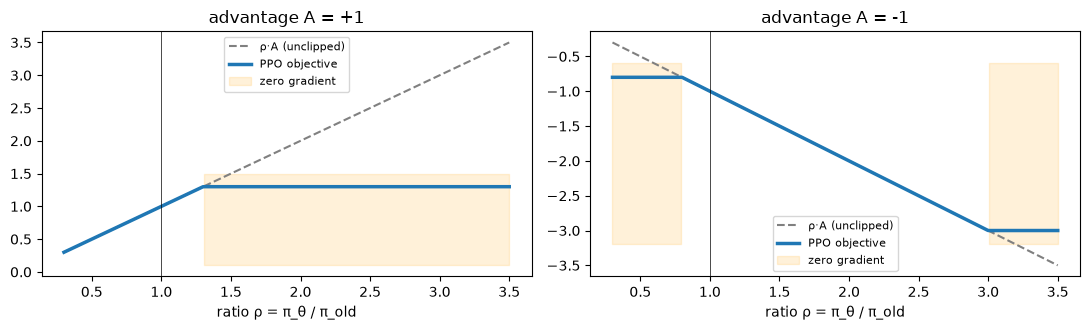

In [31]:
import matplotlib.pyplot as plt

eps_low, eps_high, clip_c = 0.2, 0.3, 3.0
ratio = np.linspace(0.3, 3.5, 600)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, A in zip(axes, [+1.0, -1.0]):
    unclipped = ratio * A
    clipped = np.clip(ratio, 1 - eps_low, 1 + eps_high) * A
    objective = np.minimum(unclipped, clipped)
    if A < 0:
        objective = np.maximum(objective, clip_c * A)  # dual-clip lower bound on the loss for A<0
    ax.plot(ratio, unclipped, "--", color="grey", label="ρ·A (unclipped)")
    ax.plot(ratio, objective, lw=2.5, label="PPO objective")
    flat = np.isclose(np.gradient(objective, ratio), 0)
    ax.fill_between(ratio, objective.min() - 0.2, objective.max() + 0.2, where=flat, color="orange", alpha=0.15, label="zero gradient")
    ax.axvline(1, color="k", lw=0.5)
    ax.set_title(f"advantage A = {A:+.0f}")
    ax.set_xlabel("ratio ρ = π_θ / π_old")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8.2 Step 1: old log-probs, and the training/inference mismatch

The trainer's first GPU job after rollouts is `_compute_old_log_prob`: the **actor** (training engine) recomputes log π_θ_old for every response token. Why not just use the log-probs vLLM already returned? Because vLLM and the training engine use different kernels, precision and batching, so their numbers differ slightly. The PPO ratio must compare like with like, otherwise ρ ≠ 1 even before any update. verl keeps vLLM's numbers as `rollout_log_probs` and can use them for importance-sampling corrections (`algorithm.rollout_correction`) or, in `bypass_mode`, directly as π_old.

Let's do the same recomputation with our HF actor and compare it with vLLM's numbers. We unpad each row first, as verl does with `use_remove_padding=True`. Running 10k mostly-pad tokens through the model would be wasteful.

In [32]:
P = train_batch.batch["prompts"].shape[1]


def unpad_row(batch, i):
    attn = batch.batch["attention_mask"][i]
    prompt = batch.batch["prompts"][i][attn[:P].bool()].tolist()
    n_resp = int(attn[P:].sum())
    return prompt, batch.batch["responses"][i][:n_resp].tolist()


rows = [unpad_row(train_batch, i) for i in range(len(train_batch))]
t0 = time.time()
old_log_probs = [response_log_probs(p, r) for p, r in rows]  # one forward per row, no grad
print(f"recomputed old log-probs for {len(rows)} rows in {time.time() - t0:.1f}s")

diffs = []
for i, lp in enumerate(old_log_probs):
    m = train_batch.batch["response_mask"][i, : len(lp)].bool().to(DEVICE)
    vllm_lp = train_batch.batch["rollout_log_probs"][i, : len(lp)].to(DEVICE)
    diffs.append((lp - vllm_lp)[m])
diffs = torch.cat(diffs)
print(f"actor vs vLLM log-prob on {diffs.numel()} trained tokens: mean |Δ| = {diffs.abs().mean():.4f}, max |Δ| = {diffs.abs().max():.3f}")
print(f"=> implied ratio exp(Δ) ranges over [{diffs.exp().min():.3f}, {diffs.exp().max():.3f}] before any update")

recomputed old log-probs for 125 rows in 3.4s
actor vs vLLM log-prob on 5619 trained tokens: mean |Δ| = 0.0099, max |Δ| = 0.762
=> implied ratio exp(Δ) ranges over [0.625, 2.143] before any update


Small on average, but a few tokens can be off by a lot. At scale, this mismatch is one of the main sources of RL instability, which is why verl offers the correction knobs above. verl also logs it every step as `rollout_corr/*` metrics (e.g. `rollout_corr/kl`), which we'll see in §10.

### 8.3 Step 2: loss, backward, optimizer step

verl's actor update (`_update_actor`, which ends up in verl's `ppo_loss`) loops:

```
for epoch in range(ppo_epochs):                                       # Calc-X: 1
    for mini_batch in split(batch, ppo_mini_batch_size * n):          # one optimizer step each
        for micro_batch in split(mini_batch, ppo_micro_batch_size):   # gradient accumulation
            log_prob = actor(micro_batch)                             # forward with grad
            loss = policy_loss_fn(old_log_prob, log_prob, advantages, response_mask)
            loss.backward()
        clip_grad_norm_(max_norm=grad_clip); optimizer.step(); optimizer.zero_grad()
```

We do the same with a single mini-batch (all our rows) and micro-batches of one row. The loss function is **literally the one the trainer uses**: Agent Lightning registers `per_rollout_mean` in verl's policy-loss registry, and we fetch it from there. Optimizer settings match Calc-X (AdamW, weight decay 0.01, grad clip 1.0), with one exception. Calc-X uses lr 1e-6 over hundreds of steps. For this *single* demonstration step we use 3e-6, so the effect stands out clearly from noise in §8.4. (Exercise 5 tries 1e-6 and 1e-5.)

Rows from zero-advantage groups have an exactly zero loss and gradient, so we skip them to save time. The result is identical.

In [33]:
from omegaconf import OmegaConf
from verl.trainer.ppo.core_algos import get_policy_loss_fn

import agentlightning.verl.per_rollout_loss  # noqa: F401  (registers "per_rollout_mean" with verl)

policy_loss_fn = get_policy_loss_fn("per_rollout_mean")
actor_cfg = OmegaConf.create({"clip_ratio": 0.2, "clip_ratio_low": eps_low, "clip_ratio_high": eps_high, "clip_ratio_c": clip_c, "global_batch_info": {}})

LR = 3e-6  # Calc-X trains with 1e-6; see the note above
optimizer = torch.optim.AdamW(actor.parameters(), lr=LR, betas=(0.9, 0.999), weight_decay=0.01)
actor.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
actor.train()

trainable_rows = [i for i in range(len(train_batch)) if adv_norm[i].abs().sum() > 0]
print(f"training on {len(trainable_rows)} rows with non-zero advantage (of {len(train_batch)})")


def ppo_mini_batch_step(row_ids):
    """One optimizer step over `row_ids`, one micro-batch per row, using the trainer's loss function."""
    metrics = {"pg_loss": 0.0, "pg_clipfrac": [], "ppo_kl": []}
    for i in row_ids:
        prompt, resp = rows[i]
        L = len(resp)
        log_prob = response_log_probs(prompt, resp, grad=True)[None]
        loss, m = policy_loss_fn(
            old_log_prob=old_log_probs[i][None],
            log_prob=log_prob,
            advantages=adv_norm[i, :L][None].to(DEVICE),
            response_mask=train_batch.batch["response_mask"][i, :L][None].to(DEVICE).bool(),
            config=actor_cfg,
        )
        loss.backward()  # gradients accumulate across rows (micro-batches)
        metrics["pg_loss"] += loss.item()
        metrics["pg_clipfrac"].append(m["actor/pg_clipfrac"])
        metrics["ppo_kl"].append(m["actor/ppo_kl"])
    grad_norm = torch.nn.utils.clip_grad_norm_(actor.parameters(), max_norm=1.0)
    if not torch.isfinite(grad_norm):
        optimizer.zero_grad(set_to_none=True)
        raise RuntimeError("non-finite gradient norm; skipped the optimizer step to keep the weights intact")
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    return {
        "pg_loss": metrics["pg_loss"], "grad_norm": grad_norm.item(),
        "pg_clipfrac": float(np.mean(metrics["pg_clipfrac"])), "ppo_kl": float(np.mean(metrics["ppo_kl"])),
    }


t0 = time.time()
step1 = ppo_mini_batch_step(trainable_rows)
print(f"optimizer step 1 done in {time.time() - t0:.1f}s:", {k: round(v, 6) for k, v in step1.items()})
print("ratio was exactly 1 for every token (θ = θ_old), so nothing could be clipped and ppo_kl is 0")

training on 55 rows with non-zero advantage (of 125)
optimizer step 1 done in 8.3s: {'pg_loss': 0.0, 'grad_norm': 0.843421, 'pg_clipfrac': 0.0, 'ppo_kl': 0.0}
ratio was exactly 1 for every token (θ = θ_old), so nothing could be clipped and ppo_kl is 0


Two things that surprise most people the first time:

* **`pg_loss` is about 0.** At ρ = 1 the loss is just −Σ A·mask over the batch, and GRPO advantages sum to zero within each group. The *value* of a policy-gradient loss means almost nothing; its *gradient* carries the signal. Don't watch `pg_loss` in a real run; watch reward, KL and clip fraction.
* **`grad_norm` is non-zero** even though the loss is about 0: positive-advantage tokens pull the weights one way and negative-advantage tokens pull them another.

### 8.4 Did it work?

Recompute the log-probs of the same responses with the **updated** weights. Two checks:

1. **The surrogate objective went up.** Σ A·(ρ − 1) over trained tokens is the quantity this gradient step was guaranteed (to first order) to increase. It was 0 before the step, since ρ = 1.
2. **Individual responses moved the intended way.** Positive-advantage responses became more likely, and negative-advantage ones became less likely.

surrogate objective Σ A·(ρ-1): 0 before the step -> +1.84e-03 after

A > 0:  26 rows, mean Δ log π(response) = +0.3219 (probability × 1.380), moved in the intended direction: 81%
A < 0:  29 rows, mean Δ log π(response) = -0.2930 (probability × 0.746), moved in the intended direction: 72%


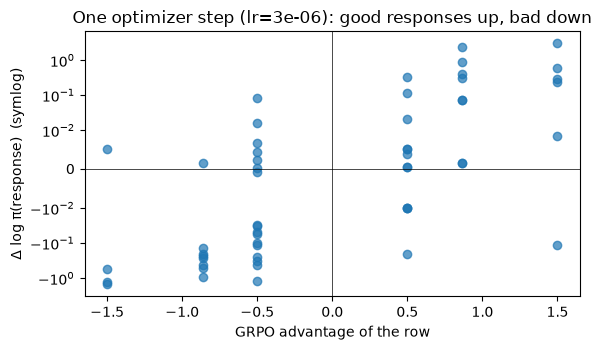

In [34]:
actor.eval()
records, surrogate_gain = [], 0.0
for i in trainable_rows:
    prompt, resp = rows[i]
    m = train_batch.batch["response_mask"][i, : len(resp)].bool().to(DEVICE)
    delta = (response_log_probs(prompt, resp) - old_log_probs[i])[m]
    surrogate_gain += (adv_norm[i, : len(resp)].to(DEVICE)[m] * (delta.exp() - 1)).sum().item()
    records.append({"row": i, "advantage": row_adv[i], "Δ mean log-prob/token": delta.mean().item(), "Δ log π(response)": delta.sum().item()})
effect = pd.DataFrame(records)

print(f"surrogate objective Σ A·(ρ-1): 0 before the step -> {surrogate_gain:+.2e} after\n")
for sign, part in [("A > 0", effect[effect.advantage > 0]), ("A < 0", effect[effect.advantage < 0])]:
    print(f"{sign}: {len(part):3d} rows, mean Δ log π(response) = {part['Δ log π(response)'].mean():+.4f} "
          f"(probability × {np.exp(part['Δ log π(response)'].mean()):.3f}), "
          f"moved in the intended direction: {(np.sign(part['Δ log π(response)']) == np.sign(part.advantage)).mean():.0%}")

plt.figure(figsize=(6, 3.6))
plt.scatter(effect.advantage, effect["Δ log π(response)"], alpha=0.7)
plt.yscale("symlog", linthresh=0.01)
plt.axhline(0, color="k", lw=0.5)
plt.axvline(0, color="k", lw=0.5)
plt.xlabel("GRPO advantage of the row")
plt.ylabel("Δ log π(response)  (symlog)")
plt.title(f"One optimizer step (lr={LR:g}): good responses up, bad down")
plt.tight_layout()
plt.show()

Notice the **asymmetry**: bad responses usually drop much more than good ones rise. A correct response that was just sampled at temperature 1 often already has a high probability, with many tokens near log p = 0, so there's little room left to push it up. A wrong response can always be made less likely. Also, not *every* row moves the intended way: all responses share the same weights, so the step improves the total objective rather than each response separately. That's one reason RL needs many samples and many small steps.

### 8.5 A second pass over the same data: now clipping matters

With `ppo_epochs > 1`, or with more than one mini-batch per step, later updates use data from a policy that has already moved. Run another step against the **same** `old_log_probs`: now ρ ≠ 1, so `ppo_kl` (an estimate of KL(π_old ‖ π_θ)) and `pg_clipfrac` (the fraction of tokens whose gradient is clipped) become non-zero. These two are the key health metrics to watch in a real run. If they grow large, we're taking steps that are too big for the trust region.

In [35]:
actor.train()
step2 = ppo_mini_batch_step(trainable_rows)
print("optimizer step 2:", {k: round(v, 6) for k, v in step2.items()})

optimizer step 2: {'pg_loss': -0.001169, 'grad_norm': 0.608538, 'pg_clipfrac': 0.008078, 'ppo_kl': -0.002294}


### 8.6 What we skipped, and what comes next

* **Reference model and KL.** Many recipes add a KL penalty to a frozen copy of the initial model (`use_kl_loss` / `use_kl_in_reward`), which needs an extra `_compute_ref_log_prob` pass. Calc-X turns this off.
* **Entropy bonus.** `entropy_coeff` is 0 in Calc-X.
* **Critic.** GRPO has none. With `adv_estimator=gae` (classic PPO), verl would also train a value network (`_update_critic`).
* **Weight sync.** The updated weights must reach the rollout engine before the next rollouts, or the data would stop being on-policy. verl does this with `checkpoint_manager.update_weights()`, which pushes the FSDP weights straight into the in-process vLLM. (Our standalone vLLM still serves the original weights.)

That was one full RL step: **rollout → batch → advantage → old log-prob → loss → update**. Let's free the GPU memory held by our hand-made actor.

In [36]:
import gc

del actor, optimizer
gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory still allocated by this kernel: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

GPU memory still allocated by this kernel: 0.07 GiB


## 9. How verl does all of this at scale

### 9.1 The same step, inside `AgentLightningRayPPOTrainer._train_step`

| What we did by hand | Trainer code (`agentlightning/verl/trainer.py`) | verl machinery behind it |
|---|---|---|
| §3 start vLLM | `init_workers()` (once) | vLLM replicas inside Ray workers (`llm_server_manager`) |
| §5 run rollouts | `_rollout()` → `AglRolloutManager.enqueue_and_wait_until_completed` | vLLM replicas woken up; endpoints registered with the Gateway |
| §6 build batch | `RolloutAdapter.get_train_data_batch` | `DataProto` |
| (not shown) | drop `is_drop_mask` rows; align rows to whole mini-batches, dropping same-reward groups first; cap with `max_ppo_update_times` | |
| (not shown) | `checkpoint_manager.sleep_replicas()` | free vLLM's KV cache so the update has GPU memory |
| §8.2 old log-probs | `_compute_old_log_prob` | actor worker group (FSDP-sharded model) |
| §8.6 ref log-probs | `_compute_ref_log_prob` (only with KL) | ref worker group |
| §7 advantages | `compute_rollout_level_advantage` → verl `compute_advantage` | runs on the driver: cheap tensor math |
| §7.4 | `normalize_advantages_by_rollout` | |
| §8.3 update | `_update_actor` → verl `ppo_loss` → `per_rollout_mean` | actor worker group: mini-batches, micro-batches, optimizer |
| §8.6 weight sync | `checkpoint_manager.update_weights()` | new weights → vLLM |

The rest of `fit()` is bookkeeping: loop over steps and epochs, run `_validate()` every `test_freq` steps (rollouts in `val` mode, greedy decoding, only `val/reward` metrics), `_save_checkpoint()` every `save_freq` steps, and log metrics.

### 9.2 The architecture: a single controller over Ray

verl uses a **single-controller** design. One driver process (the `fit()` loop above) holds the *logic*, while the *heavy compute* happens in **worker groups**: sets of Ray actors, one per GPU, that each own a shard of a model. When the driver calls `self.actor_rollout_wg.compute_log_prob(batch)`, verl splits the `DataProto` across the workers, runs the method on every GPU, and gathers the result. Scaling from 1 to 64 GPUs changes the resource pool, not the algorithm code. That's why this notebook's hand-made version and the real trainer look so similar.

On a single GPU, everything is **collocated**. The actor (FSDP, with parameters and optimizer offloaded to CPU in Calc-X's config) and the vLLM engine share the device and take turns: vLLM is awake during rollouts and sleeps during the update.

### 9.3 The config: every knob in one tree

verl is configured with Hydra/OmegaConf. Agent Lightning's `agentlightning/verl/config.yaml` extends verl's `ppo_trainer.yaml` and adds an `agentlightning:` section, and `examples/calc_x/train_calc_agent.py:build_config` layers the Calc-X overrides on top. Any key can be overridden from the command line with dotted paths, e.g. `actor_rollout_ref.rollout.n=8`.

In [37]:
from examples.calc_x.train_calc_agent import build_config

config = build_config(model=MODEL, agl_base_url=AGL_URL, agl_key=AGL_KEY)

KEYS = {
    "data.train_batch_size": "questions per step",
    "actor_rollout_ref.rollout.n": "rollouts per question (GRPO group size)",
    "actor_rollout_ref.rollout.temperature": "sampling temperature for training rollouts",
    "actor_rollout_ref.rollout.gpu_memory_utilization": "vLLM's share of GPU memory",
    "actor_rollout_ref.actor.ppo_mini_batch_size": "questions per optimizer step (multiplied by n)",
    "actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu": "rows per forward/backward (gradient accumulation)",
    "actor_rollout_ref.actor.ppo_epochs": "passes over each batch",
    "actor_rollout_ref.actor.optim.lr": "learning rate",
    "actor_rollout_ref.actor.clip_ratio_low": "ε_low",
    "actor_rollout_ref.actor.clip_ratio_high": "ε_high",
    "actor_rollout_ref.actor.policy_loss.loss_mode": "policy loss (Agent Lightning's)",
    "actor_rollout_ref.actor.use_kl_loss": "KL to reference model in the loss",
    "actor_rollout_ref.actor.entropy_coeff": "entropy bonus",
    "actor_rollout_ref.actor.fsdp_config.param_offload": "offload params to CPU when idle",
    "algorithm.adv_estimator": "advantage estimator",
    "algorithm.norm_adv_by_std_in_grpo": "divide by group std (False = Dr. GRPO)",
    "algorithm.enable_rollout_level_advantage": "Agent Lightning: advantage per rollout, not per row",
    "agentlightning.trace_aggregator.level": "Agent Lightning: trajectory or transition",
    "agentlightning.local.agent_class": "Agent Lightning: agent launched by the Controller",
    "agentlightning.rollout_timeout_seconds": "Agent Lightning: per-rollout timeout",
    "trainer.total_epochs": "epochs over the training set",
    "trainer.test_freq": "validate every N steps",
}
for key, meaning in KEYS.items():
    print(f"{key:58} = {str(OmegaConf.select(config, key)):40} # {meaning}")

data.train_batch_size                                      = 32                                       # questions per step
actor_rollout_ref.rollout.n                                = 4                                        # rollouts per question (GRPO group size)
actor_rollout_ref.rollout.temperature                      = 1.0                                      # sampling temperature for training rollouts
actor_rollout_ref.rollout.gpu_memory_utilization           = 0.6                                      # vLLM's share of GPU memory
actor_rollout_ref.actor.ppo_mini_batch_size                = 32                                       # questions per optimizer step (multiplied by n)
actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu       = 4                                        # rows per forward/backward (gradient accumulation)
actor_rollout_ref.actor.ppo_epochs                         = 1                                        # passes over each batch
actor_rollout_ref.actor

In [38]:
bs, n, mbs = config.data.train_batch_size, config.actor_rollout_ref.rollout.n, config.actor_rollout_ref.actor.ppo_mini_batch_size
micro = config.actor_rollout_ref.actor.ppo_micro_batch_size_per_gpu
print(f"""Batch-size arithmetic for one Calc-X training step:
  {bs} questions × n={n}               = {bs * n} rollouts
  each rollout → ≥1 rows (trace aggregation), say R rows in total
  mini-batch = ppo_mini_batch_size × n = {mbs} × {n} = {mbs * n} rows   → R is trimmed to a multiple of {mbs * n}
  optimizer steps per training step    = ppo_epochs × R / {mbs * n}
  each mini-batch = {mbs * n} / {micro} = {mbs * n // micro} micro-batches of {micro} rows (gradient accumulation)""")

Batch-size arithmetic for one Calc-X training step:
  32 questions × n=4               = 128 rollouts
  each rollout → ≥1 rows (trace aggregation), say R rows in total
  mini-batch = ppo_mini_batch_size × n = 32 × 4 = 128 rows   → R is trimmed to a multiple of 128
  optimizer steps per training step    = ppo_epochs × R / 128
  each mini-batch = 128 / 4 = 32 micro-batches of 4 rows (gradient accumulation)


## 10. Launch a short real training run

Time to let the real trainer do everything automatically. We reuse the Gateway and Controller that are already running, and stop our standalone vLLM, because verl starts its own engine inside Ray and needs the GPU memory.

This runs `examples/calc_x/train_calc_agent.py` (the same entrypoint `run_local.sh` uses) with overrides that keep it short:

* 3 training steps of 8 questions × 4 rollouts each;
* validation on the 20-question `test_mini.parquet` before training and after the last step;
* no checkpoint saving; metrics go to the console and a JSONL file (no W&B).

Expect about 2-5 minutes. Most of it is one-time startup: Ray, loading the FSDP actor, and starting vLLM with CUDA graphs. Selected progress lines are printed below, and the full log is in `/tmp/agl-tutorial/trainer.log`. In the full log we'll also see:
* `ERROR … hermes_tool_parser … JSONDecodeError` lines from vLLM. These mean the model wrote a malformed `<tool_call>` JSON. That's normal for a small model, the agent just gets plain text back, and it's one of the behaviors RL can train away.
* An "`Exception ignored in … DataLoader.__del__ … killed by signal`" traceback at shutdown. It's harmless dataloader teardown noise.

In [39]:
stop_service("vllm")
time.sleep(5)
free, total = torch.cuda.mem_get_info()
print(f"GPU free: {free / 2**30:.1f} / {total / 2**30:.1f} GiB")

stopped vllm
GPU free: 91.8 / 93.1 GiB


In [40]:
EXPERIMENT = "calc_x_tutorial"
METRICS_DIR = LOG_DIR / "metrics"
train_cmd = [
    sys.executable, "train_calc_agent.py",
    "--agl-base-url", AGL_URL, "--agl-key", AGL_KEY, "--model", MODEL,
    "--train-file", "data/train.parquet", "--val-file", "data/test_mini.parquet", "--run-name", "tutorial",
    "trainer.total_training_steps=3",
    "data.train_batch_size=8",
    "actor_rollout_ref.actor.ppo_mini_batch_size=8",
    "trainer.val_before_train=True",
    "trainer.save_freq=-1",
    "trainer.logger=[console,file]",
]
trainer_proc = start_service("trainer", train_cmd, cwd=REPO / "examples/calc_x", env={
    "WANDB_MODE": "disabled",
    "VERL_FILE_LOGGER_ROOT": str(METRICS_DIR),
})

INTERESTING = re.compile(r"Initial validation|Final validation|Training Progress|AglRolloutManager: completed=(\d+)/\1 |step:\d+ ")
t0 = time.time()
with open(LOG_DIR / "trainer.log", errors="replace") as log:
    while True:
        line = log.readline()
        if not line:
            if trainer_proc.poll() is not None:
                break
            time.sleep(1)
            continue
        if INTERESTING.search(line) and "vLLMHttpServer" not in line:
            line = re.sub(r"\x1b\[[0-9;]*m", "", line).strip()
            print(f"[{time.time() - t0:5.0f}s] {line[:200]}{' …' if len(line) > 200 else ''}")

print(f"\ntrainer exited with code {trainer_proc.returncode} after {time.time() - t0:.0f}s")
if trainer_proc.returncode != 0:
    raise RuntimeError(f"training failed, last log lines:\n{log_tail('trainer', 40)}")

started trainer (pid 92457), log: /tmp/agl-tutorial/trainer.log
[  104s] (_AglTaskRunner pid=95553) AglRolloutManager: completed=20/20 succeeded=20 failed=0
[  105s] (_AglTaskRunner pid=95553) ("Initial validation metrics: {'val/reward': 0.45, 'val/n_rollouts': 20, "
[  105s] (_AglTaskRunner pid=95553) step:0 - val/reward:0.45 - val/n_rollouts:20 - val/n_rollouts_w_trace:20 - val/n_rollouts_w_reward:20 - val/mean_response_length_per_turn:52.35 - val/mean_total_response_len …
[  105s] Training Progress:   0%|          | 0/3 [00:00<?, ?it/s]
[  110s] (_AglTaskRunner pid=95553) AglRolloutManager: completed=32/32 succeeded=32 failed=0
[  127s] (_AglTaskRunner pid=95553) step:1 - timing/step_start_wall:1791188533.8310816 - training/reward:0.15625 - training/n_sample:62 - training/n_rollouts:32 - training/n_rollouts_w_trace:32 - training/n_ro …
[  127s] Training Progress:  33%|███▎      | 1/3 [00:22<00:44, 22.16s/it]
[  132s] (_AglTaskRunner pid=95553) AglRolloutManager: completed=32/32 succ

### 10.1 Reading the metrics

verl logs a few hundred metrics per step. These are the ones to look at first:

| Metric | What it tells us |
|---|---|
| `training/reward` | mean reward of this step's rollouts (noisy with small batches) |
| `val/reward` | mean reward on the validation set (greedy decoding); the number we actually care about |
| `training/n_zero_adv_groups` / `training/n_groups` | how many groups carried no learning signal (§7.3) |
| `training/n_sample_trained`, `training/n_sample_dropped/same_reward` | rows that went into the update, and rows dropped (same-reward groups first) to align with mini-batches |
| `actor/pg_loss`, `actor/grad_norm` | the update itself (§8.3) |
| `actor/ppo_kl`, `actor/pg_clipfrac` | how far the policy moved within a step (§8.5); should stay small |
| `actor/entropy_loss` | mean token entropy of the policy (logged even though `entropy_coeff = 0`); collapsing entropy means less exploration |
| `rollout_corr/kl` | training-vs-inference log-prob mismatch (§8.2) |
| `response_length/mean`, `training/n_turns` | how the agent's behavior is changing |
| `timing_s/gen`, `timing_s/old_log_prob`, `timing_s/update_actor`, `timing_s/update_weights` | where the time goes (rollouts, §8.2, §8.3, weight sync) |

In [41]:
metrics_file = METRICS_DIR / "agentlightning" / f"{EXPERIMENT}.jsonl"
logged = [json.loads(line) for line in metrics_file.read_text().splitlines()]
COLUMNS = [
    "val/reward", "training/reward", "training/n_groups", "training/n_zero_adv_groups",
    "training/n_sample_collected", "training/n_sample_dropped/same_reward", "training/n_sample_trained",
    "actor/pg_loss", "actor/grad_norm", "actor/ppo_kl", "actor/pg_clipfrac", "actor/entropy_loss", "rollout_corr/kl",
    "response_length/mean", "timing_s/gen", "timing_s/old_log_prob", "timing_s/update_actor", "timing_s/update_weights", "timing_s/step",
]
metrics_df = pd.DataFrame([{"step": rec["step"], **{c: rec["data"].get(c) for c in COLUMNS}} for rec in logged]).groupby("step").last()
metrics_df.T

step,0,1,2,3
val/reward,0.45,NaN,NaN,0.400000
training/reward,NaN,0.156250,0.125000,0.312500
training/n_groups,NaN,8.000000,8.000000,8.000000
training/n_zero_adv_groups,NaN,6.000000,8.000000,6.000000
training/n_sample_collected,NaN,62.000000,60.000000,63.000000
training/n_sample_dropped/same_reward,NaN,30.000000,28.000000,31.000000
training/n_sample_trained,NaN,32.000000,32.000000,32.000000
actor/pg_loss,NaN,0.000181,0.000000,0.000131
actor/grad_norm,NaN,1.403715,0.000000,2.441280
actor/ppo_kl,NaN,0.000000,0.000000,0.000000


Step 0 holds the validation run before training. Three steps on 8 questions won't move `val/reward` meaningfully: 20 validation questions is very noisy, and a few hundred rollouts is a tiny amount of RL. With only 8 groups per step, it's also common for a step to have *all* groups with zero advantage. We'll then see `grad_norm = 0` and every row in `n_sample_dropped/same_reward`: §7.3 in action. What matters is that we can now read every line of this table and know which piece of the pipeline produced it.

The full Calc-X recipe (32 questions per step, 2 epochs over 8,192 questions = 512 steps) takes a few hours on one GPU. Run it from a terminal at the repo root:

```bash
./run_calc_x_local.sh                                   # metrics to console + examples/calc_x/metrics_log + tensorboard
# or, with Weights & Biases:
source .venv/bin/activate && cd examples/calc_x && ./run_local.sh
```

Note that `run_local.sh` uses Gateway port 8181 and cleans up with `pkill -f agl-server` / `ray stop --force`. Make sure nothing else is using port 8181, and stop this notebook's services first (next cell).

## 11. Clean up

Stop everything this notebook started (Controller, Gateway, and vLLM if it's still running).

In [4]:
stop_service("vllm")

In [3]:
stop_all()
agl.close()
print("remaining services:", list(SERVICES))

NameError: name 'agl' is not defined

## 12. Where to go from here

### Reading
* Repo docs: [Basics](https://microsoft.github.io/agent-lightning/stable/05-basics/) · [Trainer configuration](https://microsoft.github.io/agent-lightning/stable/20-trainer-configuration/) · [API Gateway](https://microsoft.github.io/agent-lightning/stable/25-api-gateway-configuration/) · [Controller](https://microsoft.github.io/agent-lightning/stable/30-controller-configuration/) · [Asynchronous training](https://microsoft.github.io/agent-lightning/stable/35-asynchronous-training/) · [Calc-X example](https://microsoft.github.io/agent-lightning/stable/50-example-calc-x/)
* Code, in reading order (`agentlightning/verl/` in the installed package, or [on GitHub](https://github.com/microsoft/agent-lightning/blob/v1.0.2/agentlightning/verl)): `trainer.py` (`_train_step`, `fit`) → `agl_rollout_manager.py` → `rollout_adapter.py` → `rollout_level_advantage.py` → `per_rollout_loss.py`
* verl internals: `.venv/lib/python3.12/site-packages/verl/trainer/ppo/ray_trainer.py` (`RayPPOTrainer`), `trainer/ppo/core_algos.py` (advantage estimators and policy losses), `workers/utils/losses.py` (`ppo_loss`)
* Papers: PPO (Schulman et al., 2017) · GRPO (DeepSeekMath, Shao et al., 2024) · DAPO (clip-higher, 2025) · Dr. GRPO (Liu et al., 2025) · HybridFlow, the verl paper (Sheng et al., 2024)
* For step-through debugging of the same rollout path, see `debug/rollout_step.py` and the "AGL: Sandbox" launch configuration in `.vscode/launch.json`.